# 6. Advanced Behavior Analysis
Stage4, 2026-01-01+, T7F / T9F only.

Task: two-armed bandit. **T7F = 7:3** and **T9F = 9:1** reward probability across arms,
so the optimal-strategy accuracy ceiling is 0.70 (T7F) and 0.90 (T9F).

**Pipeline**: raw pkl -> trial table (Phase 0) -> session features (Phase 1)
-> Q-learning parameters (Phase 2) -> HMM states (Phase 3) -> choice decoder (Phase 4).

## 1. Setup

In [1]:
import sys, os, glob, pickle, re, bisect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display

sys.path.insert(0, '/home/jyy/Documents/Beh_Ana_J')
import behave_ana

mpl.rcParams.update({'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False,
                     'figure.dpi':110,'savefig.dpi':150})

ROOT = '/home/jyy/Documents/Beh_Ana_J'
DATA_ROOT = '/mnt/HDD1/zyyk78/Stage4'
MERGED_ROOT = os.path.join(ROOT, 'merged_pkls')
OUT_DIR = os.path.join(ROOT, 'output', 'advanced_behavior')
os.makedirs(OUT_DIR, exist_ok=True)

CSV_LATEST = os.path.join(ROOT, 'analysis_results_20261027_190911.csv')
TREATMENTS = ['T7F', 'T9F']
FS = 50000.0

def trt_from_path(p):
    b = os.path.basename(p)
    m = re.match(r'^\d{8}_(.+?)_\d+(?:_\d+)?(_merged)?\.pkl$', b)
    if m: return m.group(1)
    return None

df_csv = pd.read_csv(CSV_LATEST)
df_csv['Date'] = df_csv['Date'].astype(str).str.zfill(8)
df_csv['Stage'] = df_csv['Train_file'].str.extract(r'(Stage\d)')[0]
df_csv['Treatment'] = df_csv['Train_file'].apply(trt_from_path)
df_sel = df_csv[(df_csv['Stage']=='Stage4') & (df_csv['Date']>='20260101') &
                (df_csv['Treatment'].isin(TREATMENTS))].copy().reset_index(drop=True)
print(f"CSV sessions: {len(df_sel)}  (T7F {len(df_sel[df_sel.Treatment=='T7F'])}, T9F {len(df_sel[df_sel.Treatment=='T9F'])})")
print(f"mice: {df_sel.Mouse_ID.nunique()}")

CSV sessions: 172  (T7F 89, T9F 83)
mice: 14


## 2. [Phase 0] Trial extraction

Per pkl (or merged group): `sort_events` → walk event stream, recording for each trial:
- `choice` (L/R), `outcome` (reward/omit), `correct_side` (active Mod side),
- `trial_time_s`, `iti_s`, `licks_trial`, `post_prev_reward_licks_2s`, `post_prev_omit_licks_2s`,
- `block_idx`, `trials_since_switch`.

Blackhole segments excluded (same convention as transform_sequence).

In [2]:
def safe_ts(Ev, key):
    v = Ev.get(key)
    if isinstance(v, dict):
        ts = v.get('Time_S')
        return list(ts) if ts is not None else []
    return []

def extract_trials(Ev):
    long_event = ['MinT','Blackhole']
    ignore_list = ['MinS','CamT','LickL','LickR','tMod']
    eve = behave_ana.sort_events(Ev, ignore_list=ignore_list, long_event=long_event)

    rew_ts_all = sorted(safe_ts(Ev,'SlnL') + safe_ts(Ev,'SlnR'))
    om_ts_all  = sorted(safe_ts(Ev,'ROmL') + safe_ts(Ev,'ROmR'))
    lick_ts_all = sorted(safe_ts(Ev,'LickL') + safe_ts(Ev,'LickR'))

    trials = []
    switches = []
    cur_side = None
    in_bh = False
    block_idx = 0
    t_last_outcome = None
    t_last_outcome_raw = None
    prev_outcome = None
    t0 = min(rew_ts_all[0], om_ts_all[0]) if (rew_ts_all or om_ts_all) else 0

    def licks_between(a, b):
        lo = bisect.bisect_right(lick_ts_all, a)
        hi = bisect.bisect_right(lick_ts_all, b)
        return hi - lo

    for t, e in eve:
        ts_s = (t - t0) / FS
        if e == 'Blackhole_S': in_bh = True; continue
        if e == 'Blackhole_E': in_bh = False; continue
        if in_bh: continue
        if e.startswith('Mod') and len(e) > 3 and e[-1] in ('L','R'):
            new_side = e[-1]
            if cur_side is not None and new_side != cur_side:
                switches.append({'time_s': ts_s, 'new_side': new_side, 'block_idx': block_idx})
                block_idx += 1
            elif cur_side is None:
                block_idx = 0
            cur_side = new_side
            continue
        if cur_side is None: continue
        if e.startswith('Sln') or e.startswith('ROm'):
            choice = e[-1]
            outcome = 'reward' if e.startswith('Sln') else 'omit'
            is_correct = (choice == cur_side)
            iti = (ts_s - t_last_outcome) if t_last_outcome is not None else np.nan
            post_lick = 0
            if prev_outcome is not None and t_last_outcome is not None:
                post_lick = licks_between(t_last_outcome_raw, t_last_outcome_raw + 2.0*FS)
            trials.append({
                'time_s': ts_s, 'choice': choice, 'outcome': outcome, 'correct': is_correct,
                'correct_side': cur_side, 'block_idx': block_idx,
                'iti_s': iti,
                'licks_trial': licks_between(t_last_outcome_raw or 0, t),
                'post_prev_reward_licks_2s': post_lick if prev_outcome=='reward' else np.nan,
                'post_prev_omit_licks_2s': post_lick if prev_outcome=='omit' else np.nan,
            })
            t_last_outcome = ts_s
            t_last_outcome_raw = t
            prev_outcome = outcome

    switch_trial_idx = []
    last_b = -1
    for i, tr in enumerate(trials):
        if tr['block_idx'] != last_b:
            switch_trial_idx.append(i)
            last_b = tr['block_idx']
    for i, tr in enumerate(trials):
        j = bisect.bisect_right(switch_trial_idx, i+1) - 1
        tr['trials_since_switch'] = i - switch_trial_idx[j] if j >= 0 else i

    return trials, switches

def load_event(pkl_path):
    with open(pkl_path, 'rb') as f:
        return pickle.load(f)

all_trials = []; session_summary = []; n_fail = 0
for _, row in df_sel.iterrows():
    p = row['Train_file']
    try: Ev = load_event(p)
    except Exception: n_fail += 1; continue
    trials, switches = extract_trials(Ev)
    for tr in trials:
        tr.update({'Mouse_ID': row['Mouse_ID'], 'Date': row['Date'],
                   'Treatment': row['Treatment'], 'Session_key': f"{row['Mouse_ID']}_{row['Date']}",
                   'pkl_path': p})
    all_trials.extend(trials)
    session_summary.append({'Session_key': f"{row['Mouse_ID']}_{row['Date']}", 'Mouse_ID': row['Mouse_ID'],
                            'Date': row['Date'], 'Treatment': row['Treatment'], 'pkl_path': p,
                            'n_trials': len(trials),
                            'n_correct': sum(1 for t in trials if t['correct']),
                            'n_reward': sum(1 for t in trials if t['outcome']=='reward'),
                            'n_switches': len(switches)})

df_tr = pd.DataFrame(all_trials)
df_sess = pd.DataFrame(session_summary)
print(f"trials extracted: {len(df_tr)}  sessions: {len(df_sess)}  failed: {n_fail}")
df_tr.head()

trials extracted: 130205  sessions: 172  failed: 0


,time_s,choice,outcome,correct,correct_side,block_idx,iti_s,licks_trial,post_prev_reward_licks_2s,post_prev_omit_licks_2s,trials_since_switch,Mouse_ID,Date,Treatment,Session_key,pkl_path
0,141.98264,L,omit,False,R,0,NaN,195,NaN,NaN,0,D04,20260320,T9F,D04_20260320,/mnt/HDD1/zyyk78/Stage4/D04/20260320_T9F_00.pkl
1,143.22204,L,omit,False,R,0,1.23940,4,NaN,6.0,1,D04,20260320,T9F,D04_20260320,/mnt/HDD1/zyyk78/Stage4/D04/20260320_T9F_00.pkl
2,144.41664,L,omit,False,R,0,1.19460,3,NaN,5.0,2,D04,20260320,T9F,D04_20260320,/mnt/HDD1/zyyk78/Stage4/D04/20260320_T9F_00.pkl
3,145.40588,L,omit,False,R,0,0.98924,3,NaN,4.0,3,D04,20260320,T9F,D04_20260320,/mnt/HDD1/zyyk78/Stage4/D04/20260320_T9F_00.pkl
4,162.50006,R,reward,True,R,0,17.09418,2,NaN,1.0,4,D04,20260320,T9F,D04_20260320,/mnt/HDD1/zyyk78/Stage4/D04/20260320_T9F_00.pkl


## 3. [Phase 0] QA

In [3]:
print("Per-treatment trial counts:")
print(df_tr.groupby('Treatment').agg(n_trials=('time_s','count'), n_sessions=('Session_key','nunique')))
print("\nPer-session trial count distribution:")
print(df_sess['n_trials'].describe().round(1))
print("\nSessions with <50 trials:", (df_sess['n_trials']<50).sum())
print("Sessions with 0 switches:", (df_sess['n_switches']==0).sum())

MIN_TRIALS = 50
bad_sessions = df_sess[df_sess['n_trials'] < MIN_TRIALS]['Session_key'].tolist()
df_tr_clean = df_tr[~df_tr['Session_key'].isin(bad_sessions)].copy()
print(f"\nAfter dropping sessions <{MIN_TRIALS} trials: {len(df_tr_clean)} trials, {df_tr_clean.Session_key.nunique()} sessions")

out_csv = os.path.join(ROOT, 'trials_all.csv')
df_tr_clean.to_csv(out_csv, index=False)
print(f"saved: {out_csv}  ({len(df_tr_clean)} rows)")

Per-treatment trial counts:
           n_trials  n_sessions
Treatment                      
T7F           71655          89
T9F           58550          83

Per-session trial count distribution:
count     172.0
mean      757.0
std       282.2
min       114.0
25%       624.5
50%       716.5
75%       821.5
max      3208.0
Name: n_trials, dtype: float64

Sessions with <50 trials: 0
Sessions with 0 switches: 0

After dropping sessions <50 trials: 130205 trials, 172 sessions


saved: /home/jyy/Documents/Beh_Ana_J/trials_all.csv  (130205 rows)


## 4. [Phase 1A] Rule-switch detection latency

**Paradigm note (verified in data).** Blocks are not fixed length: the task switches away
once the mouse reaches criterion (~21/30 correct = 70%) after a rule switch. Evidence:
87% of detected switches are followed by the block end within 2 trials (98% for short
blocks), min block length = 30 (= detection floor), and corr(latency, block length) ~ 0.7-0.8.
Block length is therefore the *outcome* (time to criterion), not a nuisance variable.

**Metric.** For each Mod switch, latency = trials until block-local 20-trial rolling
accuracy stays >= threshold for 10 consecutive windows. Detection is architecturally
impossible before trial 28 (19-trial window warm-up + 10 sustained windows), so
**time-to-criterion = 28 + latency**, with a measurement floor at 28. "Floor-hit"
(latency = 0) means the mouse was already at criterion at the earliest observable point -
these are the *fastest* learners and are informative, not missing.

**Censoring.** Blocks that end without detection are right-censored at 28 + maxlat.
Two causes, reported separately: (a) last block of a session (protocol truncation at
420 rewards), (b) mid-block ends where the hardware criterion (~70%) was met but the
stricter sustained-60% detector had not fired.

**Analysis.**
1. Kaplan-Meier over **all** blocks (no filtering - dropping floor-hits would bias the
   sample toward slow learners), both 60% and 55% thresholds.
2. Independent unit = mouse: per-mouse KM median, Mann-Whitney U across mice.
3. Normalized latency (latency/maxlat) is **dropped**: under the adaptive paradigm
   maxlat reflects performance, not measurement room, so normalization has no valid
   interpretation.

In [4]:
W_LAT, SUSTAIN_LAT = 20, 10
THR_MAIN, THR_ALT = 0.60, 0.55
FLOOR = (W_LAT - 1) + SUSTAIN_LAT          # 28: earliest possible detection
MIN_BLOCK = FLOOR + 1                      # 30 trials needed to observe any latency

def detect_latencies(tr_df, thr):
    out = []
    tr = tr_df.sort_values('time_s').reset_index(drop=True)
    last_block = tr['block_idx'].max()
    for b in sorted(tr['block_idx'].unique())[1:]:
        g = tr[tr['block_idx'] == b].reset_index(drop=True)
        n = len(g)
        maxlat = n - (W_LAT - 1) - SUSTAIN_LAT
        if maxlat < 1:
            continue
        acc = g['correct'].rolling(W_LAT).mean().values
        run = 0; lat = None
        for i in range(W_LAT - 1, n):
            run = run + 1 if (not np.isnan(acc[i]) and acc[i] >= thr) else 0
            if run >= SUSTAIN_LAT:
                lat = i - (W_LAT - 1) - SUSTAIN_LAT + 1
                break
        out.append({'block_idx': b, 'n_block': n, 'maxlat': maxlat,
                    'is_last_block': (b == last_block),
                    'latency': lat, 'detected': lat is not None,
                    'thresh': thr,
                    'Treatment': g['Treatment'].iloc[0],
                    'Mouse_ID': g['Mouse_ID'].iloc[0],
                    'Session_key': g['Session_key'].iloc[0]})
    return out

lat_rows = []
n_switch_total = 0; n_too_short = 0
for sk, g in df_tr_clean.groupby('Session_key'):
    sizes = g.groupby('block_idx').size()
    switch_blocks = sizes.index[1:]
    n_switch_total += len(switch_blocks)
    n_too_short += int((sizes.loc[switch_blocks] < MIN_BLOCK).sum())
    for thr in (THR_MAIN, THR_ALT):
        lat_rows.extend(detect_latencies(g, thr))

df_lat = pd.DataFrame(lat_rows)
df_lat.to_csv(os.path.join(ROOT, 'switch_latency_censored.csv'), index=False)

print(f"switch events: {n_switch_total} | dropped (<{MIN_BLOCK} trials): "
      f"{n_too_short} ({n_too_short/n_switch_total*100:.1f}%)")
d = df_lat[df_lat.thresh == THR_MAIN]
print(f"\nthr={THR_MAIN}: n={len(d)}  detected={d.detected.mean()*100:.1f}%  "
      f"floor-hit (lat=0, criterion met at trial {FLOOR})={float((d.latency==0).mean())*100:.1f}%")
print("Censoring decomposition:")
for trt in TREATMENTS:
    dd = d[d.Treatment == trt]
    cens = dd[~dd.detected]
    print(f"  {trt}: censored {len(cens)}/{len(dd)} -> "
          f"last-block(protocol) {int(cens.is_last_block.sum())}, mid-block {int((~cens.is_last_block).sum())}")
print("\nFloor-hit rate by treatment (fast-learning fraction):")
for trt in TREATMENTS:
    dd = d[d.Treatment == trt]
    print(f"  {trt}: {float((dd.latency==0).mean())*100:.1f}%")

switch events: 2624 | dropped (<30 trials): 157 (6.0%)

thr=0.6: n=2467  detected=96.8%  floor-hit (lat=0, criterion met at trial 29)=49.6%
Censoring decomposition:
  T7F: censored 46/1222 -> last-block(protocol) 19, mid-block 27
  T9F: censored 33/1245 -> last-block(protocol) 15, mid-block 18

Floor-hit rate by treatment (fast-learning fraction):
  T7F: 42.6%
  T9F: 56.4%


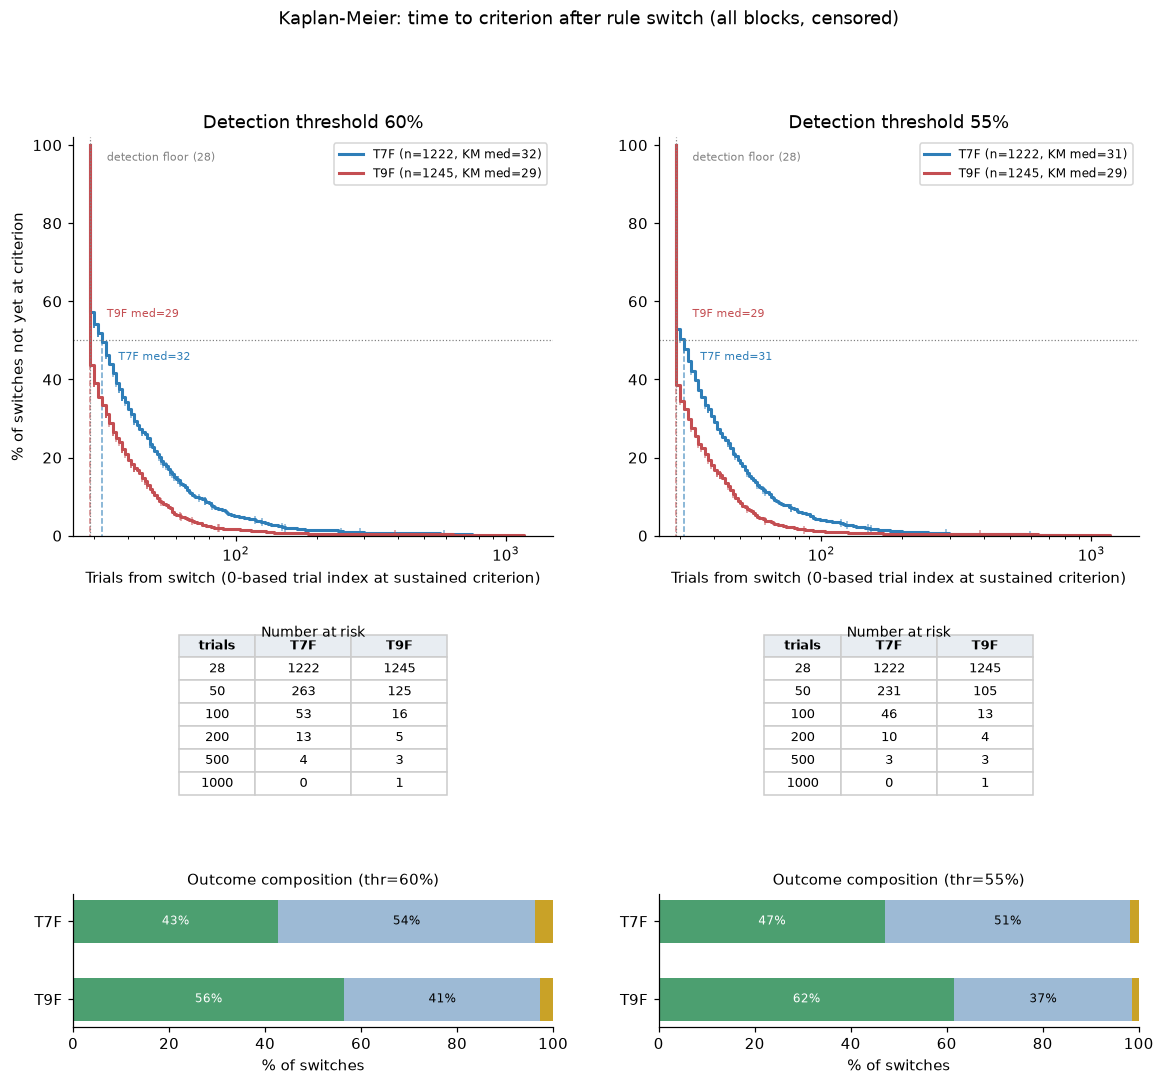

Block-level KM (visualization; inference in next cell):
 thresh Treatment  n_blocks  detected_pct  floorhit_pct  km_median  km_at_end_pct
   0.60       T7F      1222          96.2          42.6       32.0            0.0
   0.60       T9F      1245          97.3          56.4       29.0            0.0
   0.55       T7F      1222          98.2          47.1       31.0            0.0
   0.55       T9F      1245          98.6          61.5       29.0            0.0

Outcome composition (% of switches):
 thresh Treatment  floorhit_pct  delayed_pct  censored_pct
   0.60       T7F          42.6         53.6           3.8
   0.60       T9F          56.4         41.0           2.7
   0.55       T7F          47.1         51.1           1.8
   0.55       T9F          61.5         37.0           1.4

Number at risk (thr=0.6):
 trials  T7F  T9F
     28 1222 1245
     50  263  125
    100   53   16
    200   13    5
    500    4    3
   1000    0    1

Number at risk (thr=0.55):
 trials  T7F  T9F
  

In [5]:
def km_curve(times, events):
    order = np.argsort(times); t = np.asarray(times)[order]; e = np.asarray(events)[order].astype(int)
    n_at = len(t); S = 1.0; i = 0
    ts, Ss = [FLOOR], [1.0]; median = np.nan
    while i < len(t):
        ti = t[i]; same = (t == ti)
        n_events = int(e[i:][t[i:] == ti].sum())
        if n_events > 0:
            S *= (1 - n_events / n_at)
            ts.append(float(ti)); Ss.append(S)
            if np.isnan(median) and S <= 0.5:
                median = float(ti)
        n_at -= int(same.sum()); i += int(same.sum())
    return np.array(ts), np.array(Ss), median

cmap_trt = {'T7F': '#2E7EB8', 'T9F': '#C44E52'}
RISK_TICKS = [28, 50, 100, 200, 500, 1000]
CAT_COLORS = {'floor-hit (criterion at 28)': '#4C9F70',
              'delayed detection': '#9DBAD5',
              'censored (not detected)': '#C9A227'}

fig = plt.figure(figsize=(12.5, 10.5))
gs = fig.add_gridspec(3, 2, height_ratios=[3.0, 0.9, 1.0], hspace=0.55, wspace=0.22)
ax_km = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]
ax_risk = [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
ax_cat = [fig.add_subplot(gs[2, 0]), fig.add_subplot(gs[2, 1])]
km_summary = []
risk_tables, cat_stats = [], []

for pi, (ax, axc, thr) in enumerate(zip(ax_km, ax_cat, [THR_MAIN, THR_ALT])):
    # ---- KM curves + median drop-lines ----
    for trt in TREATMENTS:
        d = df_lat[(df_lat.thresh == thr) & (df_lat.Treatment == trt)]
        times = FLOOR + np.where(d.detected.values, d.latency.values, d.maxlat.values).astype(float)
        events = d.detected.values.astype(int)
        ts, Ss, med = km_curve(times, events)
        lab = (f"{trt} (n={len(d)}, KM med={med:.0f})" if not np.isnan(med)
               else f"{trt} (n={len(d)}, not reached)")
        ax.step(ts, Ss * 100, where='post', color=cmap_trt[trt], lw=2, label=lab)
        km_summary.append({'thresh': thr, 'Treatment': trt, 'n_blocks': len(d),
                           'detected_pct': round(d.detected.mean()*100, 1),
                           'floorhit_pct': round(float((d.latency==0).mean())*100, 1),
                           'km_median': med, 'km_at_end_pct': round(Ss[-1]*100, 1)})
        if not np.isnan(med):
            ax.plot([med, med], [50, 0], color=cmap_trt[trt], lw=1, ls='--', alpha=0.7)
            ytxt = 56 if trt == 'T9F' else 45
            ax.annotate(f'{trt} med={med:.0f}', (med, 50), xytext=(med*1.15, ytxt),
                        fontsize=7.5, color=cmap_trt[trt])
        # censoring ticks
        cens_t = np.sort(times[events == 0])
        if len(cens_t):
            S_at = np.interp(cens_t, ts, Ss) * 100
            ax.plot(cens_t, S_at, '|', color=cmap_trt[trt], ms=5, alpha=0.6)
    ax.axhline(50, color='gray', ls=':', lw=0.8)
    ax.axvline(FLOOR, color='gray', ls=':', lw=0.8)
    ax.text(FLOOR * 1.15, 96, 'detection floor (28)', fontsize=7, color='gray')
    ax.set_xscale('log')
    ax.set_xlim(25, 1500)
    ax.set_ylim(0, 102)
    ax.set_xlabel('Trials from switch (0-based trial index at sustained criterion)')
    ax.set_title(f'Detection threshold {thr:.0%}')
    ax.legend(fontsize=8, loc='upper right')
    if pi == 0:
        ax.set_ylabel('% of switches not yet at criterion')

    # ---- number at risk (table under the KM panel) ----
    risk = {'trials': RISK_TICKS}
    for trt in TREATMENTS:
        d = df_lat[(df_lat.thresh == thr) & (df_lat.Treatment == trt)]
        times = FLOOR + np.where(d.detected.values, d.latency.values, d.maxlat.values).astype(float)
        risk[trt] = [int((times >= t).sum()) for t in RISK_TICKS]
    rt = pd.DataFrame(risk)
    risk_tables.append(rt)
    axr = ax_risk[pi]
    axr.axis('off')
    tbl = axr.table(cellText=rt.values.tolist(), colLabels=rt.columns.tolist(),
                    colWidths=[0.16] + [0.2]*len(TREATMENTS), loc='center', cellLoc='center')
    tbl.auto_set_font_size(False); tbl.set_fontsize(8.5); tbl.scale(1, 1.25)
    for (r, c), cell in tbl.get_celld().items():
        if r == 0:
            cell.set_facecolor('#E8EDF2'); cell.set_text_props(weight='bold')
        cell.set_edgecolor('#CCCCCC')
    axr.set_title('Number at risk', fontsize=9, pad=12)

    # ---- outcome composition (floor-hit / delayed / censored) ----
    comps = []
    for trt in TREATMENTS:
        d = df_lat[(df_lat.thresh == thr) & (df_lat.Treatment == trt)]
        n = len(d)
        comps.append({'Treatment': trt,
                      'floor-hit (criterion at 28)': float((d.latency==0).mean()*100),
                      'delayed detection': float((d.detected & (d.latency>0)).mean()*100),
                      'censored (not detected)': float((~d.detected).mean()*100)})
        cat_stats.append({'thresh': thr, 'Treatment': trt,
                          'floorhit_pct': round(float((d.latency==0).mean()*100), 1),
                          'delayed_pct': round(float((d.detected & (d.latency>0)).mean()*100), 1),
                          'censored_pct': round(float((~d.detected).mean()*100), 1)})
    comp = pd.DataFrame(comps).set_index('Treatment')
    left = np.zeros(len(TREATMENTS))
    y = np.arange(len(TREATMENTS))
    for cat in comp.columns:
        vals = comp[cat].values
        axc.barh(y, vals, left=left, color=CAT_COLORS[cat], label=cat if pi == 0 else None, height=0.55)
        for yi, (v, l) in enumerate(zip(vals, left)):
            if v > 6:
                axc.text(l + v/2, yi, f'{v:.0f}%', ha='center', va='center', fontsize=8,
                         color='white' if cat == 'floor-hit (criterion at 28)' else 'black')
        left += vals
    axc.set_yticks(y); axc.set_yticklabels(TREATMENTS)
    axc.set_xlim(0, 100)
    axc.set_xlabel('% of switches')
    axc.set_title(f'Outcome composition (thr={thr:.0%})', fontsize=10)
    axc.invert_yaxis()

fig.suptitle('Kaplan-Meier: time to criterion after rule switch (all blocks, censored)', y=0.99)
fig.savefig(os.path.join(OUT_DIR, 'switch_latency_km.png'), dpi=150, bbox_inches='tight')
display(fig)
plt.close(fig)

df_km = pd.DataFrame(km_summary)
df_km.to_csv(os.path.join(ROOT, 'switch_latency_km.csv'), index=False)
pd.DataFrame(cat_stats).to_csv(os.path.join(ROOT, 'switch_latency_outcome_composition.csv'), index=False)
print("Block-level KM (visualization; inference in next cell):")
print(df_km.to_string(index=False))
print("\nOutcome composition (% of switches):")
print(pd.DataFrame(cat_stats).to_string(index=False))
for thr, rt in zip([THR_MAIN, THR_ALT], risk_tables):
    print(f"\nNumber at risk (thr={thr}):")
    print(rt.to_string(index=False))


/tmp/ipykernel_1155209/2252609972.py:72: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot([v], positions=[k], widths=0.10, vert=False, patch_artist=True, manage_ticks=False,
/tmp/ipykernel_1155209/2252609972.py:72: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot([v], positions=[k], widths=0.10, vert=False, patch_artist=True, manage_ticks=False,


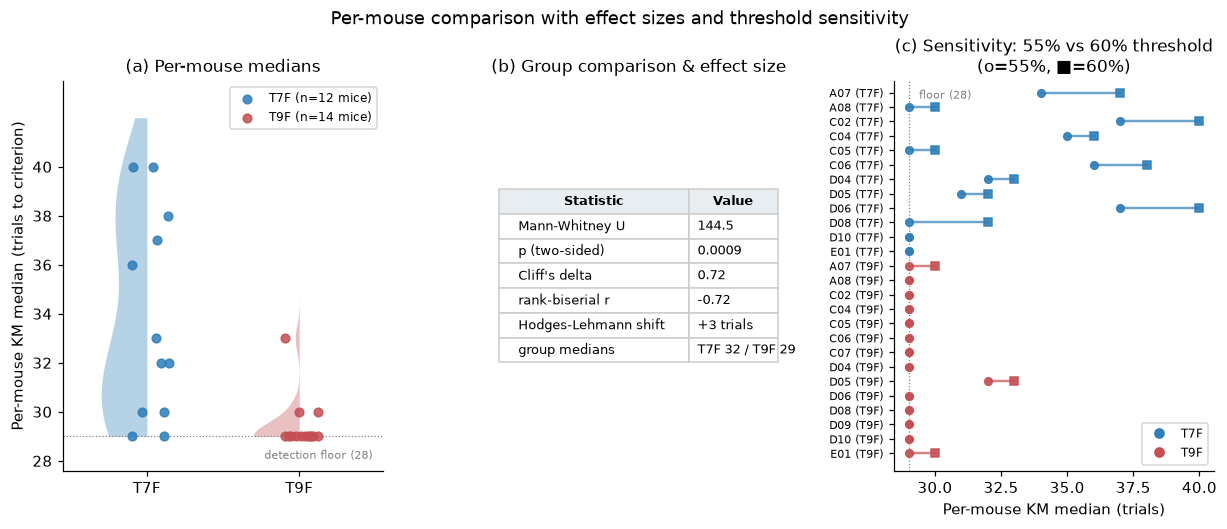

Per-mouse summary (all blocks, thr=0.60):
Mouse_ID Treatment  n_blocks  n_detected  floorhit_pct  km_median
     A07       T7F        25          23          36.0       37.0
     A08       T7F        96          93          47.9       30.0
     C02       T7F        35          33          31.4       40.0
     C04       T7F        54          54          18.5       36.0
     C05       T7F       369         362          47.7       30.0
     C06       T7F       273         256          30.8       38.0
     D04       T7F        33          31          45.5       33.0
     D05       T7F        96          93          41.7       32.0
     D06       T7F        22          17          31.8       40.0
     D08       T7F        68          66          45.6       32.0
     D10       T7F        89          88          62.9       29.0
     E01       T7F        62          60          58.1       29.0
     A07       T9F        78          73          47.4       30.0
     A08       T9F       109      

In [6]:
from scipy.stats import mannwhitneyu

cmap_trt = {'T7F': '#2E7EB8', 'T9F': '#C44E52'}
THR = THR_MAIN
dmain = df_lat[df_lat.thresh == THR]

def cliff_delta(a, b):
    """Cliff's delta = P(a>b) - P(a<b), robust to ties."""
    a = np.asarray(a); b = np.asarray(b)
    gt = sum((x > b).sum() for x in a)
    lt = sum((x < b).sum() for x in a)
    return (gt - lt) / (len(a) * len(b))

def hodges_lehmann(a, b):
    """Median of all pairwise differences a_i - b_j (HL location shift)."""
    return float(np.median(np.asarray(a)[:, None] - np.asarray(b)[None, :]))

def rank_biserial(a, b):
    U = mannwhitneyu(a, b, alternative='two-sided').statistic
    return 1 - 2 * U / (len(a) * len(b))  # >0: b tends larger

per_mouse = []
for (m, trt), g in dmain.groupby(['Mouse_ID', 'Treatment']):
    times = FLOOR + np.where(g.detected.values, g.latency.values, g.maxlat.values).astype(float)
    events = g.detected.values.astype(int)
    _, _, med = km_curve(times, events)
    per_mouse.append({'Mouse_ID': m, 'Treatment': trt, 'n_blocks': len(g),
                      'n_detected': int(g.detected.sum()),
                      'floorhit_pct': round(float((g.latency==0).mean())*100, 1),
                      'km_median': med})
df_pm = pd.DataFrame(per_mouse).sort_values(['Treatment', 'Mouse_ID'])
df_pm.to_csv(os.path.join(ROOT, 'switch_latency_per_mouse.csv'), index=False)

a = df_pm[df_pm.Treatment == 'T7F']['km_median'].dropna().values
b = df_pm[df_pm.Treatment == 'T9F']['km_median'].dropna().values
U, p = mannwhitneyu(a, b, alternative='two-sided')
cd = cliff_delta(a, b)
rb = rank_biserial(a, b)
hl = hodges_lehmann(a, b)
eff_txt = (f"Cliff's delta={cd:.2f}  r_rb={rb:.2f}\nHL shift={hl:+.0f} trials  U={U:.0f}, p={p:.4f}")

# per-mouse medians at both thresholds (for dumbbell)
per_mouse_thr = []
for thr in (THR_MAIN, THR_ALT):
    dt = df_lat[df_lat.thresh == thr]
    for (m, trt), g in dt.groupby(['Mouse_ID', 'Treatment']):
        times = FLOOR + np.where(g.detected.values, g.latency.values, g.maxlat.values).astype(float)
        events = g.detected.values.astype(int)
        _, _, med = km_curve(times, events)
        per_mouse_thr.append({'thresh': thr, 'Mouse_ID': m, 'Treatment': trt, 'km_median': med})
df_pm_thr = pd.DataFrame(per_mouse_thr)
df_pm_thr.to_csv(os.path.join(ROOT, 'switch_latency_per_mouse_both_thr.csv'), index=False)

fig = plt.figure(figsize=(13.5, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1.0, 1.15], wspace=0.38)

# ---- (a) raincloud: half-violin + box + raw points ----
ax = fig.add_subplot(gs[0])
rng = np.random.default_rng(0)
for k, trt in enumerate(TREATMENTS):
    c = cmap_trt[trt]
    v = df_pm[df_pm.Treatment == trt]['km_median'].dropna().values.astype(float)
    # half violin (KDE) on the left side of each group slot
    if len(np.unique(v)) > 1:
        from scipy.stats import gaussian_kde
        kde = gaussian_kde(v, bw_method=0.5)
        ygrid = np.linspace(max(FLOOR, v.min()), v.max() + 2, 120)
        dens = kde(ygrid)
        dens = dens / dens.max() * 0.30
        ax.fill_betweenx(ygrid, k - dens, k, color=c, alpha=0.35, lw=0)
    # box (thin) + raw points (jittered, right side)
    bp = ax.boxplot([v], positions=[k], widths=0.10, vert=False, patch_artist=True, manage_ticks=False,
                    medianprops=dict(color='black', lw=1.2),
                    boxprops=dict(facecolor='white', edgecolor=c, lw=1.2),
                    whiskerprops=dict(color=c, lw=1.0), capprops=dict(color=c, lw=1.0),
                    flierprops=dict(marker=''))
    jit = rng.uniform(-0.10, 0.16, len(v))
    ax.scatter(k + jit, v, s=32, color=c, alpha=0.85, zorder=3,
               label=f"{trt} (n={len(v)} mice)")
ax.axhline(FLOOR, color='gray', ls=':', lw=0.8)
ax.text(1.48, FLOOR - 0.55, 'detection floor (28)', ha='right', va='top', fontsize=7, color='gray')
ax.set_xticks([0, 1]); ax.set_xticklabels(TREATMENTS)
ax.set_xlim(-0.55, 1.55)
ax.set_ylim(FLOOR - 1.4, df_pm['km_median'].max() + 3.5)
ax.set_yticks([28, 30, 32, 34, 36, 38, 40])
ax.yaxis.set_major_formatter(lambda x, _: f'{x:.0f}')
ax.set_ylabel('Per-mouse KM median (trials to criterion)')
ax.set_title('(a) Per-mouse medians', fontsize=11)
ax.legend(fontsize=8, loc='upper right')

# ---- (b) MW + effect sizes ----
ax = fig.add_subplot(gs[1])
ax.axis('off')
rows = [['Mann-Whitney U', f'{U:.1f}'],
        ['p (two-sided)', f'{p:.4f}'],
        ["Cliff's delta", f'{cd:.2f}'],
        ['rank-biserial r', f'{rb:.2f}'],
        ['Hodges-Lehmann shift', f'{hl:+.0f} trials'],
        ['group medians', f'T7F {np.median(a):.0f} / T9F {np.median(b):.0f}']]
tbl = ax.table(cellText=rows, colLabels=['Statistic', 'Value'],
               colWidths=[0.68, 0.32], loc='center', cellLoc='left')
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5); tbl.scale(1, 1.35)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#E8EDF2'); cell.set_text_props(weight='bold')
    cell.set_edgecolor('#CCCCCC')
ax.set_title('(b) Group comparison & effect size', fontsize=11)

# ---- (c) dumbbell: per-mouse medians at both thresholds ----
ax = fig.add_subplot(gs[2])
piv = df_pm_thr.pivot_table(index=['Treatment', 'Mouse_ID'], columns='thresh', values='km_median')
mice = []
y = 0
for trt in TREATMENTS:
    sub = piv.loc[trt].sort_index()
    for m, row in sub.iterrows():
        y += 1
        mice.append((y, trt, m, row.get(THR_MAIN, np.nan), row.get(THR_ALT, np.nan)))
for yy, trt, m, v6, v55 in mice:
    c = cmap_trt[trt]
    if v6 == v55:
        ax.plot([v55], [yy], 'o', color=c, ms=5)
    else:
        ax.plot([v55, v6], [yy, yy], '-', color=c, lw=1.6, alpha=0.7)
        ax.plot([v55], [yy], 'o', color=c, ms=5, alpha=0.9)
        ax.plot([v6], [yy], 's', color=c, ms=5, alpha=0.9)
ax.axvline(FLOOR, color='gray', ls=':', lw=0.8)
ax.text(FLOOR + 0.4, 0.8, 'floor (28)', fontsize=7, color='gray', ha='left', va='top')
ax.set_yticks([t[0] for t in mice])
ax.set_yticklabels([f"{m} ({trt})" for _, trt, m, _, _ in mice], fontsize=7)
ax.set_ylim(0.2, len(mice) + 1.2)
ax.invert_yaxis()
ax.set_xlabel('Per-mouse KM median (trials)')
ax.set_title('(c) Sensitivity: 55% vs 60% threshold\n(o=55%, \u25a0=60%)', fontsize=11)
for trt in TREATMENTS:
    ax.plot([], [], 'o', color=cmap_trt[trt], label=trt)
ax.legend(fontsize=8, loc='lower right')

fig.suptitle('Per-mouse comparison with effect sizes and threshold sensitivity', y=1.02, fontsize=12)
fig.savefig(os.path.join(OUT_DIR, 'switch_latency_per_mouse.png'), dpi=150, bbox_inches='tight')
display(fig)
plt.close(fig)

print("Per-mouse summary (all blocks, thr=0.60):")
print(df_pm.to_string(index=False))
print(f"\n{eff_txt}")
print(f"group floor-hit: T7F {dmain[dmain.Treatment=='T7F'].latency.eq(0).mean()*100:.1f}%, "
      f"T9F {dmain[dmain.Treatment=='T9F'].latency.eq(0).mean()*100:.1f}%")


## 5. [Phase 1B] Licking dynamics

### Bout 定义
- **Bout (舔舐簇)** = 一串 ILI ≤ 0.35 s 的连续舔舐（ILI 分布在 0.35–0.45 s 处有明显谷值）。
- 数据层面的出水规则确认：`SlnL/R`（给水）和 `ROmL/R`（不给水）总是跟在同侧 trigger lick 之后（中位延迟 8.4 ms，97.6% ≤100 ms，侧别匹配 99.2%），即 **lick 触发 → 按任务概率决定是否出水**。下列 bout 统计尊重这一事件顺序。

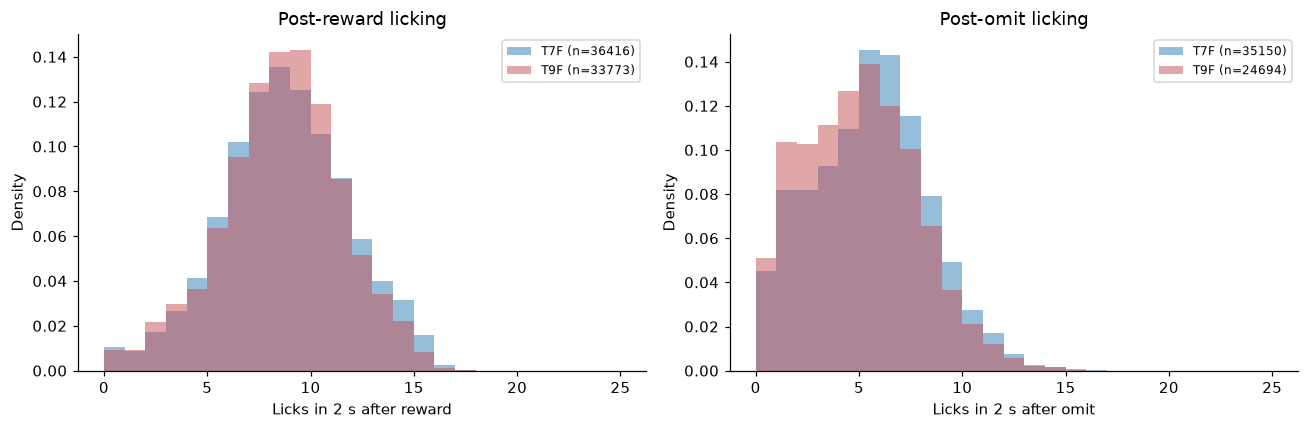

Post-outcome lick counts (mean±sd):
  T7F after reward: 8.27 ± 3.08
  T7F after omit: 5.05 ± 2.79
  T9F after reward: 8.15 ± 2.92
  T9F after omit: 4.59 ± 2.74


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, outcome_type in enumerate(['reward','omit']):
    ax = axes[j]
    col = 'post_prev_reward_licks_2s' if outcome_type=='reward' else 'post_prev_omit_licks_2s'
    for trt, c in zip(TREATMENTS, ['#2E7EB8','#C44E52']):
        vals = df_tr_clean[(df_tr_clean.Treatment==trt) & df_tr_clean[col].notna()][col]
        vals = vals[vals < 50]
        ax.hist(vals, bins=np.arange(0,26,1), density=True, alpha=0.5, color=c, label=f"{trt} (n={len(vals)})")
    ax.set_xlabel(f'Licks in 2 s after {outcome_type}'); ax.set_ylabel('Density')
    ax.set_title(f'Post-{outcome_type} licking'); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR,'post_outcome_licking.png'), bbox_inches='tight')
display(fig)
plt.close(fig)
print("Post-outcome lick counts (mean±sd):")
for trt in TREATMENTS:
    for col, lab in [('post_prev_reward_licks_2s','after reward'), ('post_prev_omit_licks_2s','after omit')]:
        v = df_tr_clean[df_tr_clean.Treatment==trt][col].dropna(); v = v[v<50]
        print(f"  {trt} {lab}: {v.mean():.2f} ± {v.std():.2f}")

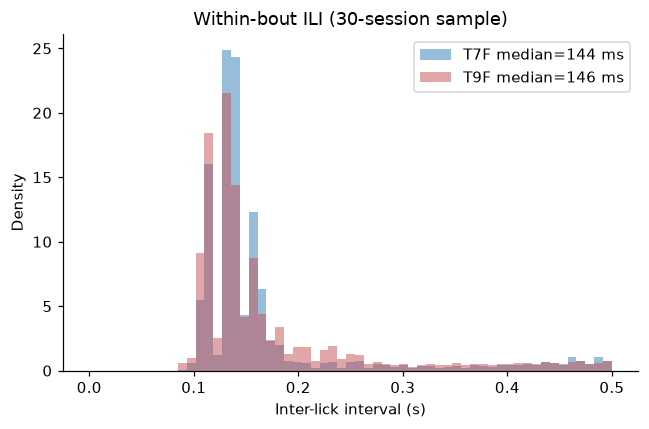

In [8]:
import random
random.seed(0)
sample_keys = random.sample(df_sess['Session_key'].tolist(), min(30, len(df_sess)))
ili_by_trt = {t: [] for t in TREATMENTS}
for sk in sample_keys:
    row = df_sess[df_sess.Session_key==sk].iloc[0]
    try: Ev = load_event(row['pkl_path'])
    except: continue
    ts = sorted(safe_ts(Ev,'LickL') + safe_ts(Ev,'LickR'))
    if len(ts) < 10: continue
    d = np.diff(ts) / FS
    d = d[d < 2.0]
    ili_by_trt[row['Treatment']].extend(d.tolist())

fig, ax = plt.subplots(figsize=(6,4))
for trt, c in zip(TREATMENTS, ['#2E7EB8','#C44E52']):
    v = np.array(ili_by_trt[trt])
    if len(v)==0: continue
    ax.hist(v, bins=np.linspace(0,0.5,60), density=True, alpha=0.5, color=c, label=f"{trt} median={np.median(v)*1000:.0f} ms")
ax.set_xlabel('Inter-lick interval (s)'); ax.set_ylabel('Density')
ax.set_title('Within-bout ILI (30-session sample)'); ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR,'ili_distribution.png'), bbox_inches='tight')
display(fig)
plt.close(fig)

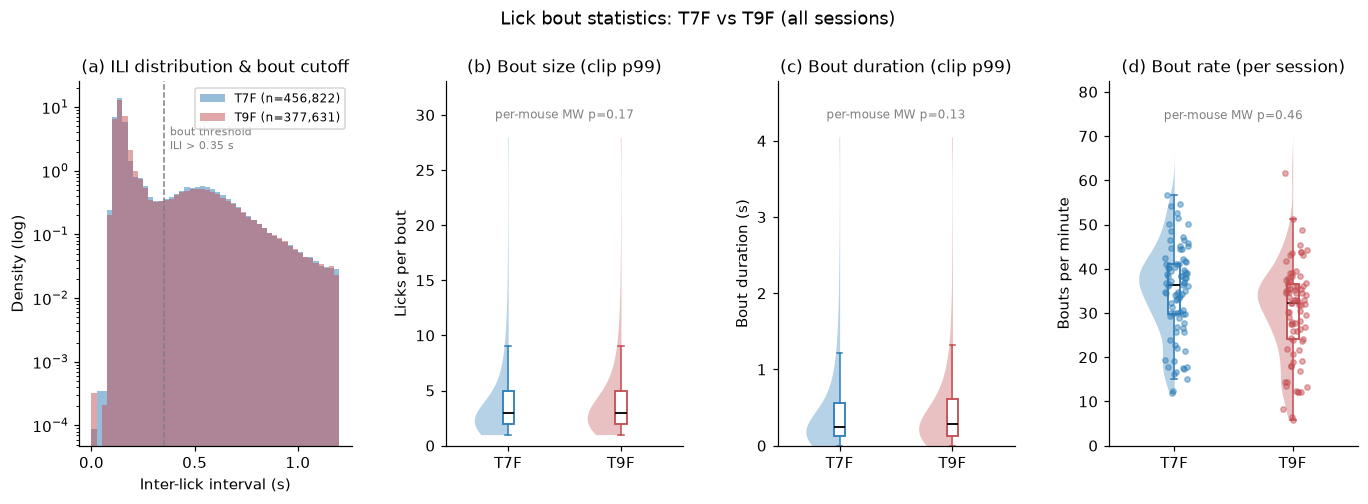

=== 出水规则核查: trial = lick 触发 → 水嘴按概率给水 ===
outcome 事件(Sln+ROm)总数: 134,920   pkl 加载失败: 0
前置同侧 lick ≤20 ms: 88.9%   ≤100 ms: 98.8%   中位延迟: 8.4 ms
无同侧前置 lick 的 outcome: 9 (0.01%)
trigger lick 侧别与 outcome 侧别一致: 99.7%
实际给水率 (最优臂 / 非最优臂): T7F 71.3% / 29.9%   T9F 89.0% / 12.2%   (范式期望 T7F≈70/30, T9F≈90/10)

=== bout ↔ trial 对应 ===
bout 总数: 198,493   (T7F 110,992 / T9F 87,501)
含 ≥1 outcome: 67.3%   含 >1 outcome(连续 trial 并入同一 bout): 0.2%   无 outcome(自发舔舐): 32.7%
含 ≥1 reward(出水)的 bout: 36.4%

Treatment  n_bouts licks/bout med[IQR] duration s med[IQR] bouts/min mouse-mean
      T7F   110992            3 [2, 5]   0.25 [0.13, 0.56]                 32.2
      T9F    87501            3 [2, 5]   0.29 [0.13, 0.61]                 28.5

Mann-Whitney (per-mouse): licks/bout p=0.174, duration p=0.129, bout rate p=0.456


In [9]:
# ---- Bout (lick cluster) statistics + water-probability-rule QA ----
# 范式: trial 由 lick 触发, 水嘴按臂概率给水(Sln=给水, ROm=不给水)。
# (1) 在 lick 流上划分 bout(ILI > 0.35 s)并对比任务间差异;
# (2) QA 核查 outcome ↔ trigger lick 对应与实际给水率, 确认分析尊重出水规则。
from scipy.stats import mannwhitneyu, gaussian_kde

BOUT_GAP = 0.35  # s, ILI 双峰谷底
cmap_trt = {'T7F': '#2E7EB8', 'T9F': '#C44E52'}

ili_by_trt = {t: [] for t in TREATMENTS}
bout_rows, sess_rows, qa_rows = [], [], []
n_load_fail = 0
for _, row in df_sess.iterrows():
    try:
        Ev = load_event(row['pkl_path'])
    except Exception:
        n_load_fail += 1
        continue
    lk = {s: np.asarray(safe_ts(Ev, 'Lick' + s), float) / FS for s in 'LR'}
    ts = np.sort(np.concatenate([lk['L'], lk['R']]))
    if len(ts) < 10:
        continue
    ev = {(o, s): np.asarray(safe_ts(Ev, o + s), float) / FS
          for o in ('Sln', 'ROm') for s in 'LR'}
    all_out = np.sort(np.concatenate([ev[('Sln','L')], ev[('Sln','R')],
                                      ev[('ROm','L')], ev[('ROm','R')]]))
    all_rew = np.sort(np.concatenate([ev[('Sln','L')], ev[('Sln','R')]]))
    ili_by_trt[row['Treatment']].extend(np.diff(ts).tolist())

    # --- QA: outcome 应紧跟同侧 trigger lick ---
    lats, side_ok, n_no_trig = [], 0, 0
    for s in 'LR':
        other = lk['R' if s == 'L' else 'L']
        for t in np.concatenate([ev[('Sln', s)], ev[('ROm', s)]]):
            i = np.searchsorted(lk[s], t, 'right') - 1
            if i < 0:
                n_no_trig += 1
                continue
            lats.append(t - lk[s][i])
            j = np.searchsorted(other, t, 'right') - 1
            side_ok += (j < 0) or (lk[s][i] >= other[j])
    lats = np.asarray(lats)
    qa_rows.append({'Treatment': row['Treatment'], 'Session_key': row['Session_key'],
                    'n_outcomes': len(all_out), 'no_same_side_trig': n_no_trig,
                    'med_trig_lat_ms': float(np.median(lats)) * 1000 if len(lats) else np.nan,
                    'pct_lat_le_20ms': 100 * float((lats <= 0.02).mean()) if len(lats) else np.nan,
                    'pct_lat_le_100ms': 100 * float((lats <= 0.10).mean()) if len(lats) else np.nan,
                    'pct_side_match': 100 * side_ok / max(len(lats), 1)})

    # --- bout 划分: ILI > BOUT_GAP 断开 ---
    br = np.where(np.diff(ts) > BOUT_GAP)[0]
    starts = np.r_[0, br + 1]
    ends = np.r_[br, len(ts) - 1]
    n_bouts = len(starts)
    li_out = np.searchsorted(ts, all_out, 'right') - 1
    li_out = li_out[li_out >= 0]
    cnt_out = np.bincount(np.searchsorted(starts, li_out, 'right') - 1, minlength=n_bouts)
    li_rew = np.searchsorted(ts, all_rew, 'right') - 1
    li_rew = li_rew[li_rew >= 0]
    cnt_rew = np.bincount(np.searchsorted(starts, li_rew, 'right') - 1, minlength=n_bouts)
    dur_min = (ts[-1] - ts[0]) / 60.0
    for b, (si, ei) in enumerate(zip(starts, ends)):
        bout_rows.append({'Treatment': row['Treatment'], 'Session_key': row['Session_key'],
                          'Mouse_ID': row['Mouse_ID'], 'n_licks': int(ei - si + 1),
                          'duration_s': float(ts[ei] - ts[si]),
                          'n_outcomes': int(cnt_out[b]), 'n_rewards': int(cnt_rew[b])})
    sess_rows.append({'Treatment': row['Treatment'], 'Session_key': row['Session_key'],
                      'Mouse_ID': row['Mouse_ID'], 'n_bouts': n_bouts,
                      'bout_rate_pm': n_bouts / dur_min})

df_bout = pd.DataFrame(bout_rows)
df_bout_sess = pd.DataFrame(sess_rows)
df_qa = pd.DataFrame(qa_rows)
df_bout.to_csv(os.path.join(ROOT, 'lick_bouts.csv'), index=False)
df_bout_sess.to_csv(os.path.join(ROOT, 'lick_bout_sessions.csv'), index=False)

# 推断用逐鼠汇总(bout 在鼠内大量重复, 不能直接当独立样本)
pm_b = df_bout.groupby(['Treatment', 'Mouse_ID']).agg(
    med_licks=('n_licks', 'median'), med_dur=('duration_s', 'median')).reset_index()
pm_r = df_bout_sess.groupby(['Treatment', 'Mouse_ID'], as_index=False).bout_rate_pm.mean()

def mw_by_treatment(tbl, col):
    a = tbl.loc[tbl.Treatment == 'T7F', col].values
    b = tbl.loc[tbl.Treatment == 'T9F', col].values
    U, p = mannwhitneyu(a, b, alternative='two-sided')
    return U, p

U_lk, p_lk = mw_by_treatment(pm_b, 'med_licks')
U_dr, p_dr = mw_by_treatment(pm_b, 'med_dur')
U_rt, p_rt = mw_by_treatment(pm_r, 'bout_rate_pm')

# ---- 一张图: ILI 阈值 + 三项 bout 统计 ----
fig = plt.figure(figsize=(15, 4.3))
gs = fig.add_gridspec(1, 4, width_ratios=[1.15, 1.0, 1.0, 1.05], wspace=0.38)

# (a) ILI 分布(log-y): within-bout 峰 + ITI 长尾, 谷底即 bout 阈值
ax = fig.add_subplot(gs[0])
bins = np.linspace(0, 1.2, 49)
for trt, c in cmap_trt.items():
    v = np.asarray(ili_by_trt[trt])
    v = v[v <= 1.2]
    ax.hist(v, bins=bins, density=True, alpha=0.5, color=c, label=f'{trt} (n={len(v):,})')
ax.axvline(BOUT_GAP, color='gray', ls='--', lw=1)
ax.text(BOUT_GAP + 0.03, ax.get_ylim()[1] * 0.15, 'bout threshold\nILI > 0.35 s',
        fontsize=7.5, color='gray')
ax.set_yscale('log')
ax.set_xlabel('Inter-lick interval (s)')
ax.set_ylabel('Density (log)')
ax.set_title('(a) ILI distribution & bout cutoff', fontsize=11)
ax.legend(fontsize=8)

def half_violin(ax, k, v, c, cap):
    """半小提琴 + 细箱线; 数值轴为左侧 y 轴, 不标注单个数据点。"""
    v = np.clip(np.asarray(v, float), None, cap)
    if len(np.unique(v)) > 1:
        kde = gaussian_kde(v, bw_method=0.35)
        yg = np.linspace(v.min(), cap, 120)
        dens = kde(yg)
        dens = dens / dens.max() * 0.30
        ax.fill_betweenx(yg, k - dens, k, color=c, alpha=0.35, lw=0)
    ax.boxplot([v], positions=[k], widths=0.10, patch_artist=True, manage_ticks=False,
               medianprops=dict(color='black', lw=1.2),
               boxprops=dict(facecolor='white', edgecolor=c, lw=1.2),
               whiskerprops=dict(color=c, lw=1.0), capprops=dict(color=c, lw=1.0),
               flierprops=dict(marker=''))

# (b) 每 bout 舔舐次数
ax = fig.add_subplot(gs[1])
cap_lk = float(np.percentile(df_bout.n_licks, 99))
for k, trt in enumerate(TREATMENTS):
    half_violin(ax, k, df_bout.loc[df_bout.Treatment == trt, 'n_licks'], cmap_trt[trt], cap_lk)
ax.text(0.5, cap_lk * 1.06, f'per-mouse MW p={p_lk:.2g}', ha='center', fontsize=8, color='gray')
ax.set_xticks([0, 1]); ax.set_xticklabels(TREATMENTS)
ax.set_xlim(-0.55, 1.55); ax.set_ylim(0, cap_lk * 1.18)
ax.set_ylabel('Licks per bout')
ax.set_title('(b) Bout size (clip p99)', fontsize=11)

# (c) bout 时长
ax = fig.add_subplot(gs[2])
cap_dr = float(np.percentile(df_bout.duration_s, 99))
for k, trt in enumerate(TREATMENTS):
    half_violin(ax, k, df_bout.loc[df_bout.Treatment == trt, 'duration_s'], cmap_trt[trt], cap_dr)
ax.text(0.5, cap_dr * 1.06, f'per-mouse MW p={p_dr:.2g}', ha='center', fontsize=8, color='gray')
ax.set_xticks([0, 1]); ax.set_xticklabels(TREATMENTS)
ax.set_xlim(-0.55, 1.55); ax.set_ylim(0, cap_dr * 1.18)
ax.set_ylabel('Bout duration (s)')
ax.set_title('(c) Bout duration (clip p99)', fontsize=11)

# (d) 每 session bout 速率
ax = fig.add_subplot(gs[3])
rng = np.random.default_rng(1)
cap_rt = float(df_bout_sess.bout_rate_pm.max()) * 1.15
for k, trt in enumerate(TREATMENTS):
    v = df_bout_sess.loc[df_bout_sess.Treatment == trt, 'bout_rate_pm'].values
    half_violin(ax, k, v, cmap_trt[trt], cap_rt)
    jit = rng.uniform(-0.08, 0.12, len(v))
    ax.scatter(k + jit, np.clip(v, None, cap_rt), s=12, color=cmap_trt[trt], alpha=0.45, zorder=3)
ax.text(0.5, cap_rt * 1.04, f'per-mouse MW p={p_rt:.2g}', ha='center', fontsize=8, color='gray')
ax.set_xticks([0, 1]); ax.set_xticklabels(TREATMENTS)
ax.set_xlim(-0.55, 1.55); ax.set_ylim(0, cap_rt * 1.16)
ax.set_ylabel('Bouts per minute')
ax.set_title('(d) Bout rate (per session)', fontsize=11)

fig.suptitle('Lick bout statistics: T7F vs T9F (all sessions)', y=1.03, fontsize=12)
fig.savefig(os.path.join(OUT_DIR, 'lick_bout_stats.png'), dpi=150, bbox_inches='tight')
display(fig)
plt.close(fig)

# ---- 出水规则 QA ----
def wmean(col):
    m = df_qa[col].notna()
    return float(np.average(df_qa.loc[m, col], weights=df_qa.loc[m, 'n_outcomes']))

n_out_total = int(df_qa.n_outcomes.sum())
n_notrig = int(df_qa.no_same_side_trig.sum())
print('=== 出水规则核查: trial = lick 触发 → 水嘴按概率给水 ===')
print(f'outcome 事件(Sln+ROm)总数: {n_out_total:,}   pkl 加载失败: {n_load_fail}')
print(f'前置同侧 lick ≤20 ms: {wmean("pct_lat_le_20ms"):.1f}%   '
      f'≤100 ms: {wmean("pct_lat_le_100ms"):.1f}%   '
      f'中位延迟: {wmean("med_trig_lat_ms"):.1f} ms')
print(f'无同侧前置 lick 的 outcome: {n_notrig} ({100 * n_notrig / n_out_total:.2f}%)')
print(f'trigger lick 侧别与 outcome 侧别一致: {wmean("pct_side_match"):.1f}%')
rr = (df_tr_clean.groupby(['Treatment', 'correct'])['outcome']
      .apply(lambda s: 100 * (s == 'reward').mean()).unstack())
line = '实际给水率 (最优臂 / 非最优臂): '
for trt in TREATMENTS:
    line += f'{trt} {rr.loc[trt, True]:.1f}% / {rr.loc[trt, False]:.1f}%   '
print(line + '(范式期望 T7F≈70/30, T9F≈90/10)')
print()
print('=== bout ↔ trial 对应 ===')
print(f'bout 总数: {len(df_bout):,}   (T7F {(df_bout.Treatment == "T7F").sum():,} / '
      f'T9F {(df_bout.Treatment == "T9F").sum():,})')
print(f'含 ≥1 outcome: {(df_bout.n_outcomes > 0).mean() * 100:.1f}%   '
      f'含 >1 outcome(连续 trial 并入同一 bout): {(df_bout.n_outcomes > 1).mean() * 100:.1f}%   '
      f'无 outcome(自发舔舐): {(df_bout.n_outcomes == 0).mean() * 100:.1f}%')
print(f'含 ≥1 reward(出水)的 bout: {(df_bout.n_rewards > 0).mean() * 100:.1f}%')
print()
rows = []
for trt in TREATMENTS:
    v = df_bout.loc[df_bout.Treatment == trt, 'n_licks']
    d = df_bout.loc[df_bout.Treatment == trt, 'duration_s']
    r = pm_r.loc[pm_r.Treatment == trt, 'bout_rate_pm']
    rows.append({'Treatment': trt, 'n_bouts': len(v),
                 'licks/bout med[IQR]': f'{v.median():.0f} [{v.quantile(.25):.0f}, {v.quantile(.75):.0f}]',
                 'duration s med[IQR]': f'{d.median():.2f} [{d.quantile(.25):.2f}, {d.quantile(.75):.2f}]',
                 'bouts/min mouse-mean': f'{r.mean():.1f}'})
print(pd.DataFrame(rows).to_string(index=False))
print(f'\nMann-Whitney (per-mouse): licks/bout p={p_lk:.3g}, duration p={p_dr:.3g}, bout rate p={p_rt:.3g}')


T9F sessions analyzed: 83, mice: 14

=== Kruskal-Wallis (session 级, 分组=小鼠) + ICC(1) ===
                metric      H     p  ICC(1)
       ILI median (ms) 54.307 0.000   0.468
           Bouts / min 53.243 0.000   0.602
   Median licks / bout 28.726 0.007   0.225
Post-reward licks (2s) 42.682 0.000   0.380
  Post-omit licks (2s) 51.566 0.000   0.566

判读: ICC 高 → 同鼠 session 聚在一起, 鼠间基线存在真实差异;
      ICC 低 → 鼠内 session 波动主导, 基线基本对齐。

=== 两两比较 (Mann-Whitney on sessions, BH 校正) ===


pairs tested: 455; BH-adjusted p<0.05: 79 (17.4%)
                metric  m1  m2    U        p    p_adj
           Bouts / min A07 A08  0.0 0.000311 0.008838
           Bouts / min A07 C02  0.0 0.000583 0.008838
           Bouts / min A07 C06  0.0 0.000103 0.008838
           Bouts / min A07 E01  0.0 0.000583 0.008838
           Bouts / min A08 D05 56.0 0.000311 0.008838
           Bouts / min C06 D05 68.0 0.000411 0.008838
           Bouts / min A07 C04  0.0 0.001166 0.013920
           Bouts / min C05 D05 60.0 0.001224 0.013920
           Bouts / min A07 C05  4.0 0.002098 0.016317
           Bouts / min A08 C02 53.0 0.002176 0.016317
           Bouts / min C04 D05 41.0 0.002331 0.016317
           Bouts / min C06 D06 40.0 0.001998 0.016317
           Bouts / min D05 E01  2.0 0.002331 0.016317
           Bouts / min A08 D06 32.0 0.004040 0.022980
           Bouts / min A08 D10 32.0 0.004040 0.022980
           Bouts / min C06 D10 39.0 0.003996 0.022980
           Bouts / min A07 C07  

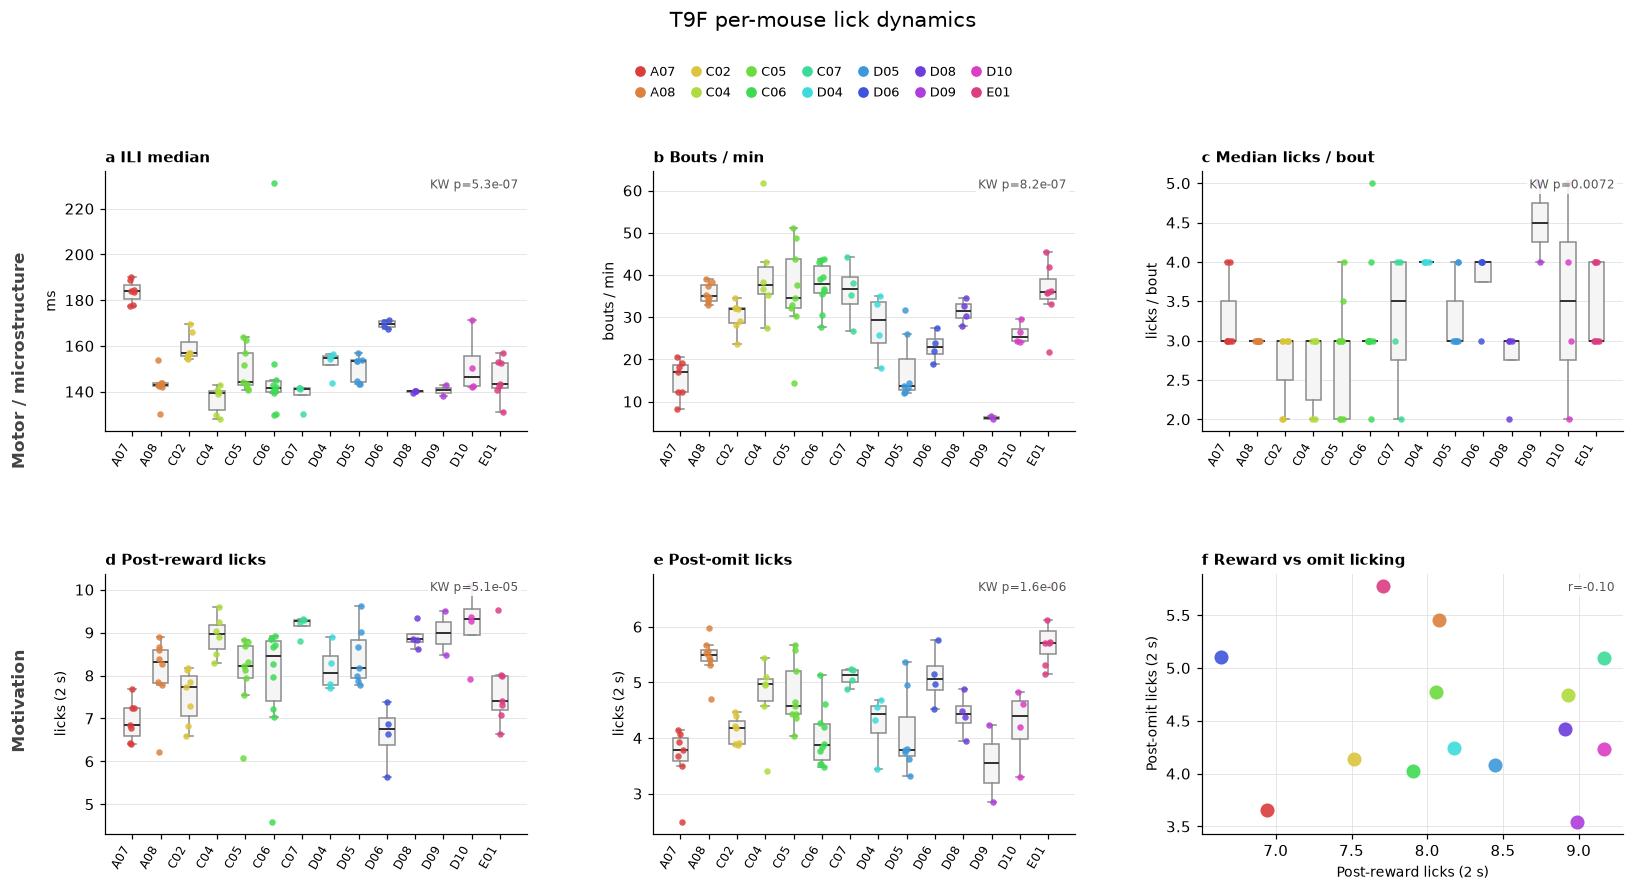


=== 逐鼠汇总表 ===
Mouse_ID  ili_median_ms  ili_p95_ms  bout_rate_pm  med_bout_size  mean_bout_size  med_bout_dur_s  mean_post_reward  mean_post_omit  mean_within_bout_dur_s  n_sessions
     A07     183.705714 1177.948286     15.354880       3.285714        5.466106        0.403990          6.944900        3.657457                0.940893           7
     A08     142.730000  848.665500     35.636926       3.000000        4.595247        0.283109          8.079006        5.453380                0.561774           8
     C02     159.195714  912.964714     30.210206       2.714286        4.810898        0.265510          7.513406        4.134253                0.700045           7
     C04     136.685000  739.582500     40.435840       2.666667        3.764522        0.237042          8.931166        4.741150                0.450391           6
     C05     149.670000  837.991000     36.136077       2.833333        4.171746        0.262438          8.059960        4.775924                0.56

In [10]:
# ---- T9F 逐鼠 lick 动力学: 运动能力 / 舔舐动机的微观分解 ----
# 目标: 在 T9F 任务内部比较各小鼠的 lick 微观结构是否对齐。
# 指标分层:
#   [运动能力] ILI 中位 / 频率上限(峰频) / bout 内时长-规模相关 → 舌运动速度
#   [舔舐动机] bout 速率 / bout 规模 / post-reward lick / post-omit lick → 驱动力与消耗
# 统计: 每鼠先 session 内汇总 → 逐鼠值 → 组内 Kruskal-Wallis + 两两 Dunn 校正
from scipy.stats import kruskal, mannwhitneyu, gaussian_kde
from itertools import combinations

TRT = 'T9F'
cmap_trt = {'T7F': '#2E7EB8', 'T9F': '#C44E52'}

# --- 1. 逐 session 计算指标(仅 T9F) ---
pm_rows, per_bout_rows, per_session_ili = [], [], []
sess9 = df_sess[df_sess.Treatment == TRT]
for _, row in sess9.iterrows():
    try:
        Ev = load_event(row['pkl_path'])
    except Exception:
        continue
    ts = np.sort(np.concatenate([np.asarray(safe_ts(Ev,'LickL'),float),
                                 np.asarray(safe_ts(Ev,'LickR'),float)])) / FS
    if len(ts) < 100:
        continue
    rew = np.sort(np.concatenate([np.asarray(safe_ts(Ev,'SlnL'),float),
                                  np.asarray(safe_ts(Ev,'SlnR'),float)])) / FS
    om  = np.sort(np.concatenate([np.asarray(safe_ts(Ev,'ROmL'),float),
                                  np.asarray(safe_ts(Ev,'ROmR'),float)])) / FS
    ili = np.diff(ts)
    per_session_ili.append({'Mouse_ID': row['Mouse_ID'], 'Session_key': row['Session_key'],
                            'ili_median_s': float(np.median(ili))})
    # bout 划分
    br = np.where(np.diff(ts) > BOUT_GAP)[0]
    starts = np.r_[0, br + 1]; ends = np.r_[br, len(ts) - 1]
    sizes = ends - starts + 1; durs = ts[ends] - ts[starts]
    li_rew = np.searchsorted(ts, rew, 'right') - 1
    li_om  = np.searchsorted(ts, om,  'right') - 1
    cnt_rew = np.bincount(np.searchsorted(starts, li_rew[li_rew>=0], 'right')-1, minlength=len(starts))
    cnt_om  = np.bincount(np.searchsorted(starts, li_om[li_om>=0],  'right')-1, minlength=len(starts))
    dur_min = (ts[-1]-ts[0])/60
    # post-outcome lick (2 s 窗口, 用原始采样点正确计算)
    lkL = np.asarray(safe_ts(Ev,'LickL'), float); lkR = np.asarray(safe_ts(Ev,'LickR'), float)
    lick_raw = np.sort(np.concatenate([lkL, lkR]))
    def post_n(ev_raw, win=2.0*FS):
        out=[]
        for t in ev_raw:
            a=np.searchsorted(lick_raw,t,'right'); b=np.searchsorted(lick_raw,t+win,'right')
            out.append(b-a)
        return np.asarray(out)
    pr = post_n(np.concatenate([safe_ts(Ev,'SlnL'), safe_ts(Ev,'SlnR')]))
    po = post_n(np.concatenate([safe_ts(Ev,'ROmL'), safe_ts(Ev,'ROmR')]))
    # bout 内 licked 时长(反映舌运动连续性): (size-1)*ILI
    within_dur = np.asarray([durs[b] for b in range(len(starts)) if sizes[b] >= 2])
    pm_rows.append({'Mouse_ID': row['Mouse_ID'], 'Session_key': row['Session_key'],
                    'n_bouts': len(starts),
                    'ili_median_ms': np.median(ili)*1000,
                    'ili_p95_ms': np.percentile(ili, 95)*1000,
                    'bout_rate_pm': len(starts)/dur_min,
                    'med_bout_size': np.median(sizes),
                    'mean_bout_size': float(sizes.mean()),
                    'med_bout_dur_s': np.median(durs),
                    'mean_post_reward': float(pr.mean()) if len(pr) else np.nan,
                    'mean_post_omit': float(po.mean()) if len(po) else np.nan,
                    'motiv_idx': float(cnt_rew.mean()) if len(cnt_rew) else np.nan,
                    'mean_within_bout_dur_s': float(within_dur.mean()) if len(within_dur) else np.nan})
    for b,(si,ei) in enumerate(zip(starts,ends)):
        per_bout_rows.append({'Mouse_ID': row['Mouse_ID'], 'Session_key': row['Session_key'],
                              'n_licks': int(ei-si+1), 'duration_s': float(ts[ei]-ts[si]),
                              'n_rewards': int(cnt_rew[b]), 'n_omit': int(cnt_om[b])})

df_pm9 = pd.DataFrame(pm_rows).sort_values('Mouse_ID').reset_index(drop=True)
df_pm9.to_csv(os.path.join(ROOT, 'lick_dynamics_per_mouse_T9F.csv'), index=False)
print(f'T9F sessions analyzed: {len(df_pm9)}, mice: {df_pm9.Mouse_ID.nunique()}')

# --- 2. 逐鼠汇总(先 session 内均值再跨 session) ---
agg = df_pm9.groupby('Mouse_ID').agg(
    ili_median_ms=('ili_median_ms','mean'),
    ili_p95_ms=('ili_p95_ms','mean'),
    bout_rate_pm=('bout_rate_pm','mean'),
    med_bout_size=('med_bout_size','mean'),
    mean_bout_size=('mean_bout_size','mean'),
    med_bout_dur_s=('med_bout_dur_s','mean'),
    mean_post_reward=('mean_post_reward','mean'),
    mean_post_omit=('mean_post_omit','mean'),
    mean_within_bout_dur_s=('mean_within_bout_dur_s','mean'),
    n_sessions=('Session_key','nunique')).reset_index().sort_values('Mouse_ID')

metrics = [('ili_median_ms','ILI median (ms)'),
           ('bout_rate_pm','Bouts / min'),
           ('med_bout_size','Median licks / bout'),
           ('mean_post_reward','Post-reward licks (2s)'),
           ('mean_post_omit','Post-omit licks (2s)')]

# --- 3. 统计: session 级 KW(鼠间差异) + ICC(1)(鼠间/总方差占比) ---
# 说明: 逐鼠聚合到 1 个值后 KW 无效(每组 n=1), 因此以 session 为观察单位;
#       ICC 补充量化"同一鼠的 session 是否更像", 即基线是否对齐。
def icc1(dfm, col):
    groups=[g[col].dropna().values for _,g in dfm.groupby('Mouse_ID')]
    groups=[g for g in groups if len(g)>0]
    k=np.mean([len(g) for g in groups])
    allv=np.concatenate(groups); grand=allv.mean()
    n=len(allv); m=len(groups)
    ssb=sum(len(g)*(g.mean()-grand)**2 for g in groups)
    ssw=sum(((g-g.mean())**2).sum() for g in groups)
    msb=ssb/(m-1); msw=ssw/(n-m)
    return (msb-msw)/(msb+(k-1)*msw) if msb+(k-1)*msw>0 else np.nan

print('\n=== Kruskal-Wallis (session 级, 分组=小鼠) + ICC(1) ===')
kw_results=[]
for col,lab in metrics:
    groups=[g[col].values for _,g in df_pm9.groupby('Mouse_ID')]
    H,p=kruskal(*groups)
    kw_results.append({'metric':lab,'H':H,'p':p,'ICC(1)':icc1(df_pm9,col)})
kw_df=pd.DataFrame(kw_results)
print(kw_df.round(3).to_string(index=False))
print('\n判读: ICC 高 → 同鼠 session 聚在一起, 鼠间基线存在真实差异;')
print('      ICC 低 → 鼠内 session 波动主导, 基线基本对齐。')

print('\n=== 两两比较 (Mann-Whitney on sessions, BH 校正) ===')
pair_rows=[]
mice=sorted(df_pm9.Mouse_ID.unique())
for col,lab in metrics:
    for m1,m2 in combinations(mice,2):
        a=df_pm9.loc[df_pm9.Mouse_ID==m1,col].values
        b=df_pm9.loc[df_pm9.Mouse_ID==m2,col].values
        U,p=mannwhitneyu(a,b,alternative='two-sided')
        pair_rows.append({'metric':lab,'m1':m1,'m2':m2,'U':U,'p':p})
pair_df=pd.DataFrame(pair_rows)
def bh(p):
    p=np.asarray(p); n=len(p); o=np.argsort(p); ranked=p[o]*n/(np.arange(n)+1)
    return np.minimum.accumulate(ranked[::-1])[::-1][np.argsort(o)]
pair_df['p_adj']=pair_df.groupby('metric')['p'].transform(lambda s: bh(s.values))
n_sig=(pair_df.p_adj<0.05).sum()
print(f'pairs tested: {len(pair_df)}; BH-adjusted p<0.05: {n_sig} ({100*n_sig/len(pair_df):.1f}%)')
sig_pair=pair_df[pair_df.p_adj<0.05].sort_values(['metric','p_adj'])
if len(sig_pair):
    print(sig_pair.to_string(index=False))
else:
    print('无显著两两差异(校正后) → 各鼠 lick 微观结构基线对齐。')

# --- 4. 一张图: 上排运动/微结构, 下排舔舐动机 ---
from matplotlib.colors import hsv_to_rgb

fig = plt.figure(figsize=(15, 8.6))
gs = fig.add_gridspec(2, 3, hspace=0.55, wspace=0.30,
                      left=0.065, right=0.985, top=0.80, bottom=0.10)

mice_order = sorted(df_pm9.Mouse_ID.unique())
n_mice = len(mice_order)
_hue = np.linspace(0, 1, n_mice, endpoint=False)
mouse_colors = {m: hsv_to_rgb(np.array([h, 0.72, 0.86]))
                for m, h in zip(mice_order, _hue)}

panels = [
    (0, 0, 'ili_median_ms',    'ILI median',          'ms',          'ILI median (ms)'),
    (0, 1, 'bout_rate_pm',     'Bouts / min',         'bouts / min', 'Bouts / min'),
    (0, 2, 'med_bout_size',    'Median licks / bout', 'licks / bout','Median licks / bout'),
    (1, 0, 'mean_post_reward', 'Post-reward licks',   'licks (2 s)', 'Post-reward licks (2s)'),
    (1, 1, 'mean_post_omit',   'Post-omit licks',     'licks (2 s)', 'Post-omit licks (2s)'),
]

rng = np.random.default_rng(2)
letters = 'abcdef'
for pid, (rr, cc, col, title, ylab, kw_lab) in enumerate(panels):
    ax = fig.add_subplot(gs[rr, cc])
    data = [df_pm9.loc[df_pm9.Mouse_ID == m, col].dropna().values for m in mice_order]
    ax.boxplot(data, positions=np.arange(n_mice), widths=0.55, patch_artist=True,
               manage_ticks=False, showfliers=False,
               medianprops=dict(color='#333333', lw=1.3),
               boxprops=dict(facecolor='#F5F5F5', edgecolor='#8C8C8C', lw=1.0),
               whiskerprops=dict(color='#8C8C8C', lw=1.0),
               capprops=dict(color='#8C8C8C', lw=1.0))
    for i, v in enumerate(data):
        jit = rng.uniform(-0.11, 0.11, len(v))
        ax.scatter(np.full(len(v), i) + jit, v, s=18,
                   color=mouse_colors[mice_order[i]], alpha=0.85,
                   linewidths=0, zorder=3)
    ax.set_xticks(np.arange(n_mice))
    ax.set_xticklabels(mice_order, rotation=60, ha='right', fontsize=8)
    ax.set_ylabel(ylab, fontsize=9)
    ax.set_title(f'{letters[pid]} {title}', loc='left', fontsize=10, fontweight='bold')
    ax.grid(axis='y', color='#DDDDDD', lw=0.6, alpha=0.8, zorder=0)
    p_val = kw_df.loc[kw_df.metric == kw_lab, 'p'].values[0]
    ax.text(0.98, 0.97, f'KW p={p_val:.2g}', transform=ax.transAxes,
            fontsize=8, va='top', ha='right', color='#555555',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))

# (f) post-reward vs post-omit: 动机分解散点(每鼠一色, 标签见图例)
ax = fig.add_subplot(gs[1, 2])
for m in mice_order:
    row_m = agg[agg.Mouse_ID == m]
    ax.scatter(row_m['mean_post_reward'].values[0], row_m['mean_post_omit'].values[0],
               s=85, color=mouse_colors[m], alpha=0.9, linewidths=0, zorder=3)
ax.set_xlabel('Post-reward licks (2 s)', fontsize=9)
ax.set_ylabel('Post-omit licks (2 s)', fontsize=9)
ax.set_title('f Reward vs omit licking', loc='left', fontsize=10, fontweight='bold')
ax.grid(color='#DDDDDD', lw=0.6, alpha=0.8, zorder=0)
r_f = np.corrcoef(agg['mean_post_reward'], agg['mean_post_omit'])[0, 1]
ax.text(0.98, 0.97, f'r={r_f:.2f}', transform=ax.transAxes, fontsize=8,
        va='top', ha='right', color='#555555',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))

# 分组行标签
fig.text(0.013, 0.60, 'Motor / microstructure', rotation=90, va='center', ha='center',
         fontsize=11, fontweight='bold', color='#444444')
fig.text(0.013, 0.24, 'Motivation', rotation=90, va='center', ha='center',
         fontsize=11, fontweight='bold', color='#444444')

fig.suptitle('T9F per-mouse lick dynamics', y=0.97, fontsize=14)
_handles = [plt.Line2D([], [], marker='o', ls='', markersize=6,
                       color=mouse_colors[m], label=m) for m in mice_order]
fig.legend(handles=_handles, ncol=7, loc='upper center', bbox_to_anchor=(0.5, 0.925),
           frameon=False, fontsize=8.5, columnspacing=1.1,
           handletextpad=0.25, handlelength=1.0)

fig.savefig(os.path.join(OUT_DIR, 'lick_dynamics_per_mouse_T9F.png'),
            dpi=200, bbox_inches='tight')
display(fig)
plt.close(fig)

print('\n=== 逐鼠汇总表 ===')
print(agg.to_string(index=False))


## 6. [Phase 1C] PCA behavioral manifold

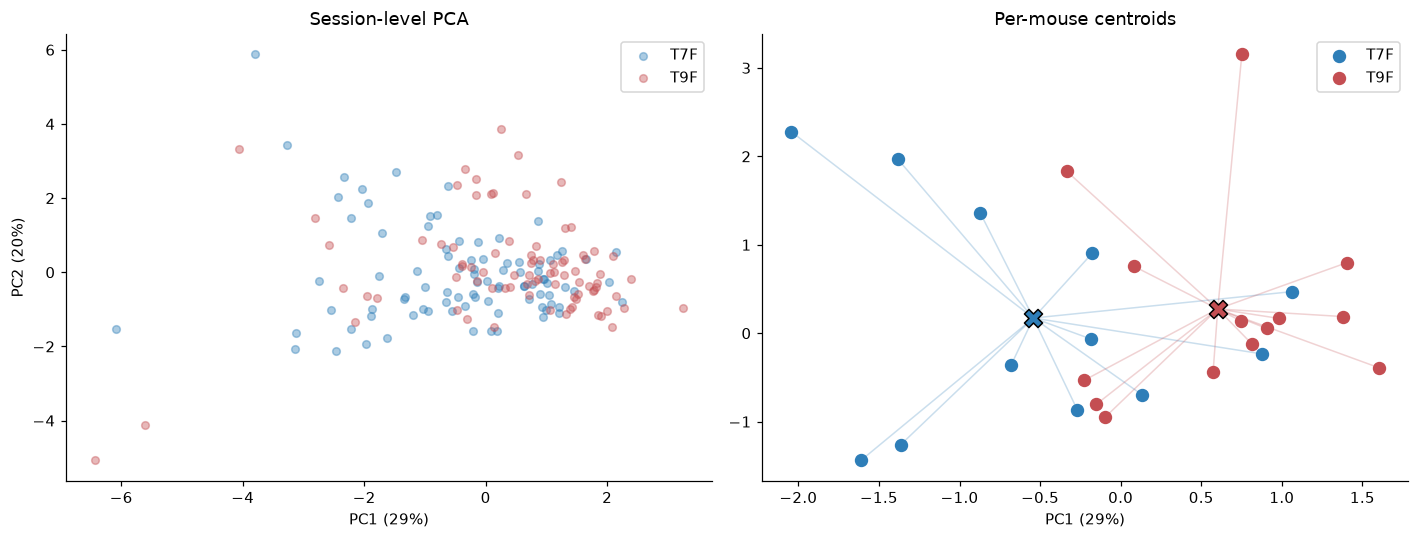

Explained variance: [0.289 0.197]

Loadings (PC1, PC2):
  Accuracy                        +0.59  +0.03
  Learning_auc                    +0.57  +0.06
  log_lr                          -0.00  -0.45
  avg_licks_after_reward          -0.21  +0.40
  avg_licks_after_noreward        -0.02  +0.33
  Switching Latency               -0.44  -0.33
  Incorrect Switch                -0.25  +0.40
  MeanRewardInterval_s            -0.06  +0.46
  Cumulative_Attempt_auc          -0.11  -0.20


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

FEATS = ['Accuracy','Learning_auc','log_lr','avg_licks_after_reward','avg_licks_after_noreward',
         'Switching Latency','Incorrect Switch','MeanRewardInterval_s','Cumulative_Attempt_auc']
df_sess2 = df_sess.copy(); df_sess2['Date'] = df_sess2['Date'].astype(str)
df_pca = df_sel.merge(df_sess2[['Session_key','Mouse_ID','Date','n_trials']], on=['Mouse_ID','Date'], how='inner')
df_pca = df_pca.dropna(subset=FEATS)
X = StandardScaler().fit_transform(df_pca[FEATS].values)
pca = PCA(n_components=2); Z = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
ax = axes[0]
for trt, c in zip(TREATMENTS, ['#2E7EB8','#C44E52']):
    m = df_pca['Treatment']==trt
    ax.scatter(Z[m,0], Z[m,1], c=c, alpha=0.4, s=25, label=trt)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.0f}%)')
ax.set_title('Session-level PCA'); ax.legend()
ax = axes[1]
for trt, c in zip(TREATMENTS, ['#2E7EB8','#C44E52']):
    m = df_pca['Treatment']==trt
    tmp = pd.DataFrame(Z[m], columns=['pc1','pc2']); tmp['mouse'] = df_pca[m]['Mouse_ID'].values
    cent = tmp.groupby('mouse').mean()
    ax.scatter(cent['pc1'], cent['pc2'], c=c, s=60, label=trt, zorder=3)
    gmean = cent.mean()
    for _, r in cent.iterrows():
        ax.plot([r['pc1'], gmean['pc1']], [r['pc2'], gmean['pc2']], color=c, alpha=0.25, lw=1)
    ax.scatter(gmean['pc1'], gmean['pc2'], marker='X', s=140, c=c, edgecolors='k', zorder=4)
ax.set_title('Per-mouse centroids')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}%)'); ax.legend()
plt.tight_layout()
display(fig)
plt.close(fig)
fig.savefig(os.path.join(OUT_DIR,'pca_manifold.png'), bbox_inches='tight')
print("Explained variance:", pca.explained_variance_ratio_.round(3))
print("\nLoadings (PC1, PC2):")
for f, l1, l2 in zip(FEATS, pca.components_[0], pca.components_[1]):
    print(f"  {f:30s}  {l1:+.2f}  {l2:+.2f}")

## 7. [Phase 1D] Rolling accuracy & within-session dynamics

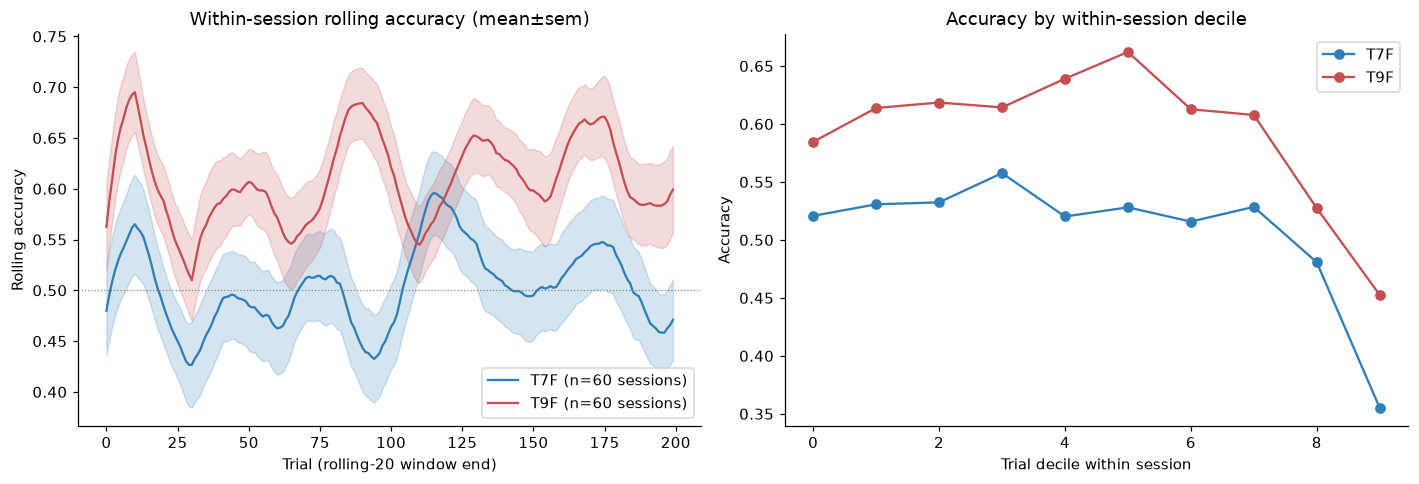

Done.


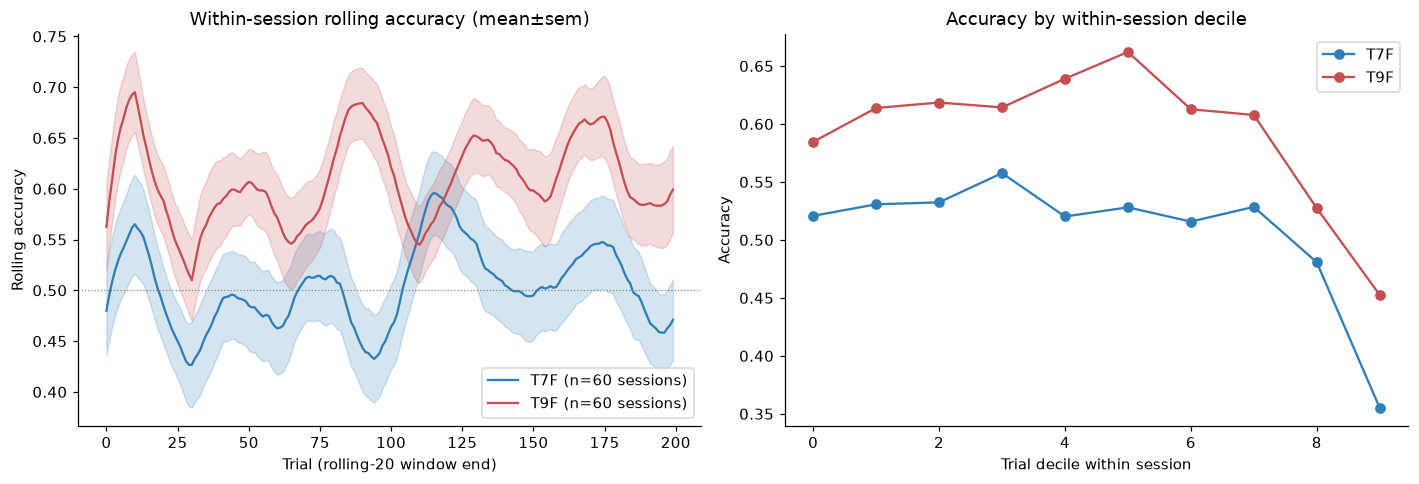

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
colors_map = {'T7F':'#2E7EB8','T9F':'#C44E52'}
ax = axes[0]
for trt in TREATMENTS:
    sessions = df_tr_clean[df_tr_clean.Treatment==trt]['Session_key'].unique()[:60]
    curves = []
    for sk in sessions:
        g = df_tr_clean[df_tr_clean.Session_key==sk].sort_values('time_s')
        if len(g) < 40: continue
        r = g['correct'].rolling(20).mean().values[19:]
        curves.append(r[:200])
    L = max(len(c) for c in curves)
    M = np.full((len(curves), L), np.nan)
    for i, c in enumerate(curves): M[i,:len(c)] = c
    m = np.nanmean(M, axis=0); s = np.nanstd(M, axis=0)/np.sqrt(len(curves))
    ax.plot(np.arange(len(m)), m, color=colors_map[trt], label=f"{trt} (n={len(curves)} sessions)")
    ax.fill_between(np.arange(len(m)), m-s, m+s, color=colors_map[trt], alpha=0.2)
ax.set_xlabel('Trial (rolling-20 window end)'); ax.set_ylabel('Rolling accuracy')
ax.set_title('Within-session rolling accuracy (mean±sem)')
ax.legend(); ax.axhline(0.5, color='gray', ls=':', lw=0.8)

ax = axes[1]
for trt in TREATMENTS:
    sub = df_tr_clean[df_tr_clean.Treatment==trt].copy()
    sub['trial_decile'] = pd.qcut(sub.groupby('Session_key').cumcount(), 10, labels=False, duplicates='drop')
    acc_by_d = sub.groupby('trial_decile')['correct'].mean()
    ax.plot(acc_by_d.index, acc_by_d.values, 'o-', color=colors_map[trt], label=trt)
ax.set_xlabel('Trial decile within session'); ax.set_ylabel('Accuracy')
ax.set_title('Accuracy by within-session decile'); ax.legend()
plt.tight_layout()
display(fig)
fig.savefig(os.path.join(OUT_DIR,'within_session_dynamics.png'), bbox_inches='tight')
print("Done.")

## 7.5. [Phase 2] Q-learning model fitting

Per mouse-treatment: fit 4-parameter Q-learning with separate positive/negative learning rates
(alpha+ / alpha-), inverse temperature beta, and choice stickiness. MLE with L-BFGS-B, 3 restarts.

Plain reading: high alpha+ = fast learning after reward; high alpha- = fast un-learning after omission;
high beta = more deterministic choice; stickiness = tendency to repeat previous choice.


In [13]:
from scipy.optimize import minimize
import time as _time

def qll_ql(params, g):
    ap, am, beta, stick = params
    if not (0.001 < ap < 1 and 0.001 < am < 1 and 0.01 < beta < 50 and -5 < stick < 5):
        return 1e10
    choice = (g['choice'] == 'R').astype(int).values
    rew = (g['outcome'] == 'reward').astype(int).values
    Q = np.array([0.5, 0.5]); last_c = None; ll = 0.0
    for t in range(len(g)):
        c = choice[t]
        bias = stick if (last_c is not None and last_c == c) else 0.0
        z = beta * (Q[c] - Q[1-c]) + bias
        ll += -np.log1p(np.exp(-z)) if c == 1 else -np.log1p(np.exp(z))
        r = rew[t]
        if r: Q[c] += ap * (1 - Q[c])
        else: Q[c] += am * (0 - Q[c])
        last_c = c
    return -ll

def fit_ql(g, n_restarts=3):
    best = None
    x0s = [[0.3,0.3,3,0], [0.1,0.1,5,1], [0.5,0.5,2,-0.5]]
    for i in range(n_restarts):
        x0 = x0s[i % len(x0s)]
        try:
            r = minimize(qll_ql, x0, args=(g,), method='L-BFGS-B',
                         bounds=[(1e-3,0.999),(1e-3,0.999),(0.01,50),(-5,5)])
            if best is None or r.fun < best.fun:
                best = r
        except Exception:
            pass
    return best

t0 = _time.time()
ql_rows = []
for (m, trt), gm in df_tr_clean.groupby(['Mouse_ID', 'Treatment']):
    r = fit_ql(gm)
    ql_rows.append({'Mouse_ID': m, 'Treatment': trt, 'n_trials': len(gm),
                    'alpha_plus': r.x[0], 'alpha_minus': r.x[1],
                    'beta': r.x[2], 'stickiness': r.x[3], 'negLL': r.fun})
df_ql = pd.DataFrame(ql_rows)
df_ql.to_csv(os.path.join(ROOT, 'qlearning_params.csv'), index=False)
print(f"Fitted {len(df_ql)} mouse-treatment combos in {_time.time()-t0:.0f}s")
print(df_ql[['Mouse_ID','Treatment','alpha_plus','alpha_minus','beta','stickiness']].round(3).to_string(index=False))


KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cmap_trt = {'T7F': '#2E7EB8', 'T9F': '#C44E52'}
ax = axes[0]
for trt in TREATMENTS:
    d = df_ql[df_ql.Treatment == trt]
    ax.scatter(d.alpha_plus, d.alpha_minus, c=cmap_trt[trt], s=60, label=trt, alpha=0.8)
    for _, r in d.iterrows():
        ax.annotate(r.Mouse_ID, (r.alpha_plus, r.alpha_minus), fontsize=7, alpha=0.7)
ax.set_xlabel('alpha+ (reward LR)'); ax.set_ylabel('alpha- (omission LR)')
ax.set_title('Learning rates'); ax.legend()
ax = axes[1]
for trt in TREATMENTS:
    d = df_ql[df_ql.Treatment == trt]
    ax.scatter(d.beta, d.stickiness, c=cmap_trt[trt], s=60, label=trt, alpha=0.8)
    for _, r in d.iterrows():
        ax.annotate(r.Mouse_ID, (r.beta, r.stickiness), fontsize=7, alpha=0.7)
ax.set_xlabel('beta (inverse temperature)'); ax.set_ylabel('stickiness')
ax.set_title('Exploitation & stickiness'); ax.legend()
ax = axes[2]
pos = np.arange(3)
cols3 = ['alpha_plus', 'alpha_minus', 'beta']
for j, col in enumerate(cols3):
    for trt in TREATMENTS:
        v = df_ql[df_ql.Treatment == trt][col]
        x = pos[j] + (0.15 if trt == 'T7F' else -0.15)
        ax.scatter(x, v.median(), c=cmap_trt[trt], marker='D', s=60, zorder=3)
        ax.vlines(x, v.quantile(0.25), v.quantile(0.75), color=cmap_trt[trt], lw=2, alpha=0.5)
ax.set_xticks(pos); ax.set_xticklabels(['alpha+', 'alpha-', 'beta'])
ax.set_title('Medians [IQR] by treatment')
for trt in TREATMENTS:
    ax.plot([], [], 'D', color=cmap_trt[trt], label=trt)
ax.legend()
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'qlearning_params.png'), bbox_inches='tight')
print('\nPer-treatment medians:')
for col in ['alpha_plus', 'alpha_minus', 'beta', 'stickiness']:
    for trt in TREATMENTS:
        v = df_ql[df_ql.Treatment == trt][col]
        print(f'  {col:15s} {trt}: {v.median():.3f} [{v.quantile(0.25):.3f}-{v.quantile(0.75):.3f}]')


In [ ]:
# --- Phase 3: Gaussian HMM on trial-level features (per session) ---
import time, warnings, pickle
warnings.filterwarnings('ignore')

W_HMM = 20

def build_session_features(g, W=W_HMM):
    g = g.sort_values('time_s').reset_index(drop=True)
    acc = np.full(len(g), np.nan)
    for b, gb in g.groupby('block_idx', sort=True):
        c = gb['correct'].astype(float)
        r = c.rolling(W, min_periods=10).mean()
        e = c.expanding().mean()
        acc[gb.index.values] = r.fillna(e).values
    acc = np.nan_to_num(acc, nan=0.5)
    licks = g['licks_trial'].astype(float).values
    iti = g['iti_s'].astype(float)
    iti = iti.fillna(iti.median()).values
    post = g['post_prev_reward_licks_2s'].fillna(
        g['post_prev_omit_licks_2s']).astype(float).fillna(0).values
    F = np.column_stack([acc, np.log1p(licks),
                         np.log1p(np.clip(iti, 0, None)), np.log1p(post)])
    return g, F

def _log_emission(X, mu, var):
    K = mu.shape[0]
    out = np.empty((X.shape[0], K))
    for k in range(K):
        out[:, k] = -0.5 * (((X - mu[k])**2 / var[k]).sum(1)
                            + np.log(2 * np.pi * var[k]).sum())
    return out

def fit_hmm(X, K, seed=0, max_iter=100, tol=2e-3, sticky=2.0, nonsticky=0.2):
    # Baum-Welch for a K-state Gaussian HMM with a sticky transition prior.
    T, D = X.shape
    rng = np.random.default_rng(seed)
    if seed == 0:
        order = np.argsort(X[:, 0])
        cuts = np.linspace(0, T, K + 1).astype(int)
        assign = np.zeros(T, dtype=int)
        for k in range(K):
            assign[order[cuts[k]:cuts[k+1]]] = k
    else:
        assign = rng.integers(0, K, T)
    mu = np.zeros((K, D)); var = np.zeros((K, D)); gvar = X.var(0) + 1e-2
    for k in range(K):
        m = assign == k
        if m.sum() < 5:
            mu[k] = X[rng.integers(0, T)]; var[k] = gvar
        else:
            mu[k] = X[m].mean(0); var[k] = X[m].var(0) + 1e-2
    A = np.full((K, K), 0.05); np.fill_diagonal(A, 0.90); A /= A.sum(1, keepdims=True)
    pi = np.full(K, 1.0 / K)
    prior = np.full((K, K), nonsticky); np.fill_diagonal(prior, sticky)
    ll = -np.inf
    for it in range(max_iter):
        B = np.exp(_log_emission(X, mu, var))
        alpha = np.empty((T, K)); beta = np.empty((T, K)); c = np.empty(T)
        alpha[0] = pi * B[0]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = alpha[t-1] @ A * B[t]
            c[t] = alpha[t].sum(); alpha[t] /= c[t]
        beta[-1] = 1.0
        for t in range(T-2, -1, -1):
            beta[t] = A @ (beta[t+1] * B[t+1]) / c[t+1]
        gamma = alpha * beta
        gamma /= gamma.sum(1, keepdims=True)
        xi = np.einsum('ti,ij,tj->ij', alpha[:-1], A, beta[1:] * B[1:])
        ll_new = np.log(c).sum()
        w = gamma.sum(0)
        pi = gamma[0] + 1e-8; pi /= pi.sum()
        A = xi + prior; A /= A.sum(1, keepdims=True)
        for k in range(K):
            mu[k] = (gamma[:, k] @ X) / (w[k] + 1e-8)
            var[k] = ((X - mu[k])**2 * gamma[:, k:k+1]).sum(0) / (w[k] + 1e-8) + 1e-3
        if it > 2 and abs(ll_new - ll) < tol * max(abs(ll_new), 1.0):
            ll = ll_new; break
        ll = ll_new
    n_free = (K - 1) + K * (K - 1) + 2 * K * D
    bic = -2 * ll + n_free * np.log(T)
    perm = np.argsort(mu[:, 0])  # states sorted by rolling accuracy (low -> high)
    return {'K': K, 'logL': ll, 'bic': bic, 'mu': mu[perm], 'var': var[perm],
            'A': A[np.ix_(perm, perm)], 'states': gamma[:, perm].argmax(1).astype(np.int8)}

CACHE = os.path.join(ROOT, 'hmm_results.pkl')
csv_path = os.path.join(ROOT, 'trials_all.csv')
if os.path.exists(CACHE) and os.path.getmtime(CACHE) > os.path.getmtime(csv_path):
    with open(CACHE, 'rb') as f:
        hmm_results = pickle.load(f)
    print('loaded cached HMM results:', len(hmm_results), 'sessions')
else:
    t0 = time.time()
    hmm_results = {}
    for sk, g in df_tr_clean.groupby('Session_key'):
        gg, F = build_session_features(g)
        if np.isnan(F).any():
            continue
        hmm_results[sk] = {}
        for K in (2, 3):
            best = None
            for seed in range(3):
                f = fit_hmm(F, K, seed=seed)
                if best is None or f['bic'] < best['bic']:
                    best = f
            hmm_results[sk][K] = best
    with open(CACHE, 'wb') as f:
        pickle.dump(hmm_results, f)
    print(f'fitted {len(hmm_results)} sessions in {time.time()-t0:.0f}s')

bic2 = [r[2]['bic'] for r in hmm_results.values()]
bic3 = [r[3]['bic'] for r in hmm_results.values()]
n3 = sum(1 for a, b in zip(bic2, bic3) if b < a)
print(f'BIC: K=2 better in {len(bic2)-n3} sessions, K=3 better in {n3} / {len(bic2)}')

In [ ]:
# --- State interpretation + model-selection figure ---
mu_by_state = np.array([r[3]['mu'] for r in hmm_results.values()])
feat_names = ['rolling_acc', 'log_licks', 'log_iti', 'log_post_licks']
print('K=3 state means (averaged across sessions):')
for k in range(3):
    vals = ', '.join('%s=%.2f' % (nm, mu_by_state[:, k, j].mean())
                     for j, nm in enumerate(feat_names))
    print('  State %d: %s' % (k, vals))

occ3 = np.array([np.bincount(r[3]['states'], minlength=3) / len(r[3]['states'])
                 for r in hmm_results.values()])
sk_order = {sk: i for i, sk in enumerate(hmm_results)}
sess_info = df_sess.set_index('Session_key')[['Treatment', 'Mouse_ID']]
print()
print('Mean occupancy by treatment (K=3):')
for trt in TREATMENTS:
    sks = [sk for sk in hmm_results if sess_info.loc[sk, 'Treatment'] == trt]
    m = occ3[[sk_order[sk] for sk in sks]].mean(0)
    print('  %s: state0=%.3f state1=%.3f state2=%.3f (n=%d sessions)' % (trt, *m, len(sks)))

figA, axes = plt.subplots(1, 3, figsize=(15, 4.2))
rng = np.random.default_rng(0)
ax = axes[0]
ax.scatter(rng.normal(2, 0.06, len(bic2)), bic2, s=10, alpha=0.35, color='#888', label='K=2')
ax.scatter(rng.normal(3, 0.06, len(bic3)), bic3, s=10, alpha=0.35, color='#2E7EB8', label='K=3')
ax.set_xticks([2, 3]); ax.set_xlabel('Number of states (K)')
ax.set_ylabel('BIC (lower = better)')
ax.set_title(f'Model selection: K=3 wins {n3}/{len(bic2)} sessions')
ax.legend()

ax = axes[1]
m = mu_by_state.mean(0); s = mu_by_state.std(0) / np.sqrt(len(mu_by_state))
xpos = np.arange(4); w = 0.26
for k in range(3):
    ax.bar(xpos + (k - 1) * w, m[k], w, yerr=s[k], capsize=2,
           color=['#C44E52', '#DD8452', '#55A868'][k], label=f'State {k}')
ax.set_xticks(xpos)
ax.set_xticklabels(['roll acc', 'log licks', 'log ITI', 'log post-licks'])
ax.set_ylabel('Feature mean (+/- sem)')
ax.set_title('Emission means (K=3)')
ax.legend(fontsize=8)

ax = axes[2]
xpos = np.arange(3); w = 0.35
for i, (trt, c) in enumerate(zip(TREATMENTS, ['#2E7EB8', '#C44E52'])):
    sks = [sk for sk in hmm_results if sess_info.loc[sk, 'Treatment'] == trt]
    ax.bar(xpos + (i - 0.5) * w, occ3[[sk_order[sk] for sk in sks]].mean(0), w,
           color=c, label=trt)
ax.set_xticks(xpos); ax.set_xticklabels(['State 0', 'State 1', 'State 2'])
ax.set_ylabel('Mean occupancy')
ax.set_title('State occupancy by treatment')
ax.legend()
plt.tight_layout()
display(figA)
figA.savefig(os.path.join(OUT_DIR, 'hmm_model_states.png'), bbox_inches='tight')

In [ ]:
# --- Example session rasters (one representative session per treatment) ---
from matplotlib.colors import ListedColormap
state_cmap = ListedColormap(['#C44E52', '#DD8452', '#55A868'])

figB, axes = plt.subplots(2, 1, figsize=(13, 5.5))
for ax, trt in zip(axes, TREATMENTS):
    cand = df_sess[(df_sess.Treatment == trt) & (df_sess.Session_key.isin(hmm_results))].copy()
    med_n = cand['n_trials'].median()
    cand = cand.iloc[(cand['n_trials'] - med_n).abs().argsort()]
    sk = cand.iloc[0]['Session_key']
    g = df_tr_clean[df_tr_clean.Session_key == sk].sort_values('time_s').reset_index(drop=True)
    h = hmm_results[sk][3]['states']
    acc20 = g['correct'].rolling(20, min_periods=10).mean()
    ax.imshow(h[None, :], aspect='auto', cmap=state_cmap, interpolation='nearest',
              extent=[0, len(g), 0, 1], vmin=-0.5, vmax=2.5)
    ax2 = ax.twinx()
    ax2.plot(acc20.values, color='k', lw=1.1)
    ax2.set_ylim(0, 1); ax2.set_ylabel('Rolling acc (20)')
    for b, gb in g.groupby('block_idx'):
        if b > 0:
            ax.axvline(gb.index[0], color='w', lw=0.9, ls='--', alpha=0.9)
    ax.set_yticks([]); ax.set_xlim(0, len(g))
    ax.set_title(f'{sk} ({trt}) - n={len(g)} trials')
    ax.set_xlabel('Trial')
plt.tight_layout()
display(figB)
figB.savefig(os.path.join(OUT_DIR, 'hmm_example_sessions.png'), bbox_inches='tight')

In [ ]:
# --- State occupancy vs trials-since-switch + per-mouse State-0 occupancy ---
bin_labels = ['1-10', '11-20', '21-40', '41-80', '81-160', '>160']
rows = []
for sk, r in hmm_results.items():
    g = df_tr_clean[df_tr_clean.Session_key == sk].sort_values('time_s')
    if len(g) != len(r[3]['states']):
        continue
    bins = np.array([0, 10, 20, 40, 80, 160, 10**9])
    bidx = np.clip(np.digitize(g['trials_since_switch'].values, bins) - 1, 0, 5)
    for st, b in zip(r[3]['states'], bidx):
        rows.append({'state': int(st), 'bin': bin_labels[b]})
dd = pd.DataFrame(rows)
ct = pd.crosstab(dd['bin'], dd['state'], normalize='index')
ct = ct.reindex(index=bin_labels, columns=[0, 1, 2], fill_value=0)

figC, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
xpos = np.arange(len(ct)); bottom = np.zeros(len(ct))
for k, c in enumerate(['#C44E52', '#DD8452', '#55A868']):
    ax.bar(xpos, ct[k].values, bottom=bottom, color=c, width=0.7, label=f'State {k}')
    bottom += ct[k].values
ax.set_xticks(xpos); ax.set_xticklabels(ct.index, rotation=30)
ax.set_ylabel('State occupancy')
ax.set_xlabel('Trials since last rule switch')
ax.set_title('State occupancy vs time since switch')
ax.legend(fontsize=8)

ax = axes[1]
pm = {}
for sk, r in hmm_results.items():
    mouse = sk.rsplit('_', 1)[0]
    pm.setdefault(mouse, []).append((r[3]['states'] == 0).mean())
pm_s = pd.Series({m: np.mean(v) for m, v in pm.items()}).sort_values()
ax.bar(range(len(pm_s)), pm_s.values, color='#C44E52', alpha=0.85)
ax.set_xticks(range(len(pm_s)))
ax.set_xticklabels(pm_s.index, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('State-0 occupancy')
ax.set_title('Per-mouse perseverative-state occupancy')
plt.tight_layout()
display(figC)
figC.savefig(os.path.join(OUT_DIR, 'hmm_state_dynamics.png'), bbox_inches='tight')
print('Top-3 mice in State 0:',
      ', '.join('%s %.0f%%' % (m, v * 100) for m, v in pm_s.tail(3).items()))

## 8. [Phase 3] HMM behavioral states

Each trial is assumed to come from a hidden behavioral state. We observe per trial:
block-local rolling accuracy, licks, ITI, post-outcome licks. A Gaussian-emission HMM
with a **sticky transition prior** (states persist) is fit per session; K=2 vs K=3 chosen by BIC
(3 restarts each).

Plain reading: low-accuracy state (<0.30) = disengaged / persisting wrong;
mid (~0.45) = guessing / transition; high (~0.70) = engaged.


In [ ]:
import warnings, time
warnings.filterwarnings('ignore')
HMM_W = 20

def build_hmm_features(g, W=HMM_W):
    g = g.sort_values('time_s').reset_index(drop=True)
    acc = np.full(len(g), np.nan)
    for b, gb in g.groupby('block_idx', sort=True):
        c = gb['correct'].astype(float)
        r = c.rolling(W, min_periods=10).mean()
        e = c.expanding().mean()
        acc[gb.index.values] = r.fillna(e).values
    acc = np.nan_to_num(acc, nan=0.5)
    licks = g['licks_trial'].astype(float).values
    iti = g['iti_s'].astype(float)
    iti = iti.fillna(iti.median()).values
    post = (g['post_prev_reward_licks_2s']
            .fillna(g['post_prev_omit_licks_2s']).astype(float).fillna(0).values)
    return g, np.column_stack([acc, np.log1p(licks),
                               np.log1p(np.clip(iti, 0, None)), np.log1p(post)])

def _log_emission(X, mu, var):
    K = mu.shape[0]; out = np.empty((X.shape[0], K))
    for k in range(K):
        out[:, k] = -0.5 * (((X - mu[k])**2 / var[k]).sum(1)
                            + np.log(2*np.pi*var[k]).sum())
    return out

def fit_hmm(X, K, seed=0, max_iter=100, tol=2e-3, sticky=2.0, nonsticky=0.2):
    T, D = X.shape; rng = np.random.default_rng(seed)
    if seed == 0:
        order = np.argsort(X[:, 0]); cuts = np.linspace(0, T, K+1).astype(int)
        assign = np.zeros(T, dtype=int)
        for k in range(K):
            assign[order[cuts[k]:cuts[k+1]]] = k
    else:
        assign = rng.integers(0, K, T)
    mu = np.zeros((K, D)); var = np.zeros((K, D)); gvar = X.var(0) + 1e-2
    for k in range(K):
        m = assign == k
        if m.sum() < 5:
            mu[k] = X[rng.integers(0, T)]; var[k] = gvar
        else:
            mu[k] = X[m].mean(0); var[k] = X[m].var(0) + 1e-2
    A = np.full((K, K), 0.05); np.fill_diagonal(A, 0.90); A /= A.sum(1, keepdims=True)
    pi = np.full(K, 1.0 / K)
    prior = np.full((K, K), nonsticky); np.fill_diagonal(prior, sticky)
    ll = -np.inf
    for it in range(max_iter):
        B = np.exp(_log_emission(X, mu, var))
        alpha = np.empty((T, K)); beta = np.empty((T, K)); c = np.empty(T)
        alpha[0] = pi * B[0]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = alpha[t-1] @ A * B[t]; c[t] = alpha[t].sum(); alpha[t] /= c[t]
        beta[-1] = 1.0
        for t in range(T-2, -1, -1):
            beta[t] = A @ (beta[t+1] * B[t+1]) / c[t+1]
        gamma = alpha * beta; gamma /= gamma.sum(1, keepdims=True)
        xi = np.einsum('ti,ij,tj->ij', alpha[:-1], A, beta[1:] * B[1:])
        ll_new = np.log(c).sum()
        w = gamma.sum(0)
        pi = gamma[0] + 1e-8; pi /= pi.sum()
        A = xi + prior; A /= A.sum(1, keepdims=True)
        for k in range(K):
            mu[k] = (gamma[:, k] @ X) / (w[k] + 1e-8)
            var[k] = ((X - mu[k])**2 * gamma[:, k:k+1]).sum(0) / (w[k] + 1e-8) + 1e-3
        if it > 2 and abs(ll_new - ll) < tol * max(abs(ll_new), 1.0):
            ll = ll_new; break
        ll = ll_new
    n_free = (K - 1) + K * (K - 1) + 2 * K * D
    bic = -2 * ll + n_free * np.log(T)
    perm = np.argsort(mu[:, 0])
    return {'K': K, 'logL': ll, 'bic': bic, 'mu': mu[perm], 'var': var[perm],
            'A': A[np.ix_(perm, perm)], 'gamma': gamma[:, perm]}

t0 = time.time()
hmm_results = {}
for sk, g in df_tr_clean.groupby('Session_key'):
    gg, F = build_hmm_features(g)
    if np.isnan(F).any():
        continue
    hmm_results[sk] = {}
    for K in (2, 3):
        best = None
        for seed in range(3):
            f = fit_hmm(F, K, seed=seed)
            if best is None or f['bic'] < best['bic']:
                best = f
        hmm_results[sk][K] = best
print(f"Fitted {len(hmm_results)} sessions (K=2,3 x 3 restarts) in {time.time()-t0:.1f}s")

bic2 = np.array([r[2]['bic'] for r in hmm_results.values()])
bic3 = np.array([r[3]['bic'] for r in hmm_results.values()])
print(f"BIC: K=2 better in {(bic2 < bic3).sum()} sessions, K=3 better in {(bic3 < bic2).sum()}")
HMM_K = 3 if (bic3 < bic2).sum() > (bic2 < bic3).sum() else 2
print(f"Chosen K = {HMM_K}")

rows_state, rows_sess = [], []
for sk, r in hmm_results.items():
    f = r[HMM_K]; h = f['gamma'].argmax(1)
    g = df_tr_clean[df_tr_clean.Session_key == sk].sort_values('time_s').reset_index(drop=True)
    rows_state.append(pd.DataFrame({
        'Session_key': sk, 'trial_idx': np.arange(len(g)),
        'state': h, 'p_state': f['gamma'].max(1)}))
    occ = np.bincount(h, minlength=HMM_K) / len(h)
    rows_sess.append({'Session_key': sk, 'Treatment': g['Treatment'].iloc[0],
                      'Mouse_ID': g['Mouse_ID'].iloc[0], 'n_trials': len(g),
                      **{f'occ_s{k}': occ[k] for k in range(HMM_K)}})
df_hmm_trial = pd.concat(rows_state, ignore_index=True)
df_hmm_sess = pd.DataFrame(rows_sess)
df_hmm_trial.to_csv(os.path.join(ROOT, 'hmm_trials.csv'), index=False)
df_hmm_sess.to_csv(os.path.join(ROOT, 'hmm_session_summary.csv'), index=False)
print(f"saved: hmm_trials.csv ({len(df_hmm_trial)} rows), hmm_session_summary.csv ({len(df_hmm_sess)} rows)")


In [ ]:
feat_names = ['rolling_acc', 'log_licks', 'log_ITI', 'log_post_licks']
mu_avg = np.array([r[HMM_K]['mu'] for r in hmm_results.values()])
cmap = ['#C44E52', '#DD8452', '#2E7EB8']
occ_cols = [f'occ_s{k}' for k in range(HMM_K)]
width = 0.8 / HMM_K

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
x = np.arange(len(feat_names))
for k in range(HMM_K):
    m = mu_avg[:, k, :]
    ax.bar(x + (k - (HMM_K-1)/2) * width, m.mean(0), width,
           yerr=m.std(0) / np.sqrt(len(m)), color=cmap[k], label=f'State {k}')
ax.set_xticks(x); ax.set_xticklabels(feat_names, rotation=20, ha='right')
ax.set_ylabel('Feature mean'); ax.set_title('HMM state emission means'); ax.legend()

ax = axes[1]
occ_by_trt = df_hmm_sess.groupby('Treatment')[occ_cols].mean()
xt = np.arange(len(TREATMENTS))
for k in range(HMM_K):
    vals = [occ_by_trt.loc[t, f'occ_s{k}'] for t in TREATMENTS]
    ax.bar(xt + (k - (HMM_K-1)/2) * width, vals, width, color=cmap[k], label=f'State {k}')
ax.set_xticks(xt); ax.set_xticklabels(TREATMENTS)
ax.set_ylabel('Mean occupancy'); ax.set_title('State occupancy by treatment'); ax.legend()
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'hmm_states.png'), bbox_inches='tight')

print('Mean emission per state (averaged over sessions):')
for k in range(HMM_K):
    print('  State %d: ' % k + ', '.join(f'{n}={v:.2f}' for n, v in zip(feat_names, mu_avg[:, k, :].mean(0))))
print('\nOccupancy by treatment:')
print(occ_by_trt.round(3))


In [ ]:
cand = df_hmm_sess[(df_hmm_sess[occ_cols].min(1) >= 0.15) & (df_hmm_sess.n_trials >= 300)]
if len(cand) == 0:
    cand = df_hmm_sess.iloc[[df_hmm_sess[occ_cols].min(1).values.argmax()]]
sk_ex = cand.sort_values('n_trials').Session_key.iloc[0]
row_ex = df_hmm_sess[df_hmm_sess.Session_key == sk_ex].iloc[0]
g_ex = df_tr_clean[df_tr_clean.Session_key == sk_ex].sort_values('time_s').reset_index(drop=True)
gg_ex, F_ex = build_hmm_features(g_ex)
state_ex = hmm_results[sk_ex][HMM_K]['gamma'].argmax(1)

fig, ax = plt.subplots(figsize=(13, 3.2))
runs = []; start = 0
for i in range(1, len(state_ex)):
    if state_ex[i] != state_ex[i-1]:
        runs.append((start, i, state_ex[i-1])); start = i
runs.append((start, len(state_ex), state_ex[-1]))
for s, e, st in runs:
    ax.axvspan(s, e, color=cmap[st], alpha=0.35, lw=0)
ax.plot(np.arange(len(g_ex)), F_ex[:, 0], color='k', lw=1.2)
sw = g_ex[g_ex['trials_since_switch'] == 0].index.tolist()
for s in sw:
    ax.axvline(s, color='gray', ls='--', lw=0.7)
ax.set_xlabel('Trial'); ax.set_ylabel('Rolling accuracy (20-trial)')
ax.set_title(f'Example session {sk_ex} ({row_ex.Treatment}) - HMM states as background')
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'hmm_example_session.png'), bbox_inches='tight')
print('Example:', sk_ex, '| occupancy:', ', '.join(f'S{k}={row_ex[f"occ_s{k}"]:.2f}' for k in range(HMM_K)))
print('Gray dashed lines = rule switches; colors = HMM state (red=0, orange=1, blue=2).')


In [ ]:
mice = sorted(df_hmm_sess.Mouse_ID.unique())
xt = np.arange(len(mice))
fig, ax = plt.subplots(figsize=(9, 4.2))
for k in range(HMM_K):
    v = [df_hmm_sess[df_hmm_sess.Mouse_ID == m][f'occ_s{k}'].mean() for m in mice]
    ax.bar(xt + (k - (HMM_K-1)/2) * width, v, width, color=cmap[k], label=f'State {k}')
ax.set_xticks(xt); ax.set_xticklabels(mice, rotation=45, ha='right')
ax.set_ylabel('Mean occupancy (all sessions)'); ax.set_title('Per-mouse HMM state occupancy')
ax.legend()
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'hmm_per_mouse.png'), bbox_inches='tight')
print('Per-mouse State-0 occupancy range:',
      f"{df_hmm_sess.groupby('Mouse_ID')['occ_s0'].mean().min():.2f} - "
      f"{df_hmm_sess.groupby('Mouse_ID')['occ_s0'].mean().max():.2f}")


## 9. [Phase 4] Choice decoder

Predict the mouse choice (L vs R) on each trial from trial-history features using
per-mouse logistic regression:
- previous choice, previous outcome (reward/omit),
- previous choice x previous outcome interaction (win-stay / lose-shift),
- trials since last rule switch.

Reported per mouse: 5-fold cross-validated AUC and regression coefficients.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

DEC_COLS = ['choice_lag1', 'outcome_lag1', 'choice_x_outcome', 'trials_since_switch']

def build_decoder_features(g):
    g = g.sort_values('time_s').reset_index(drop=True)
    d = pd.DataFrame(index=g.index)
    d['choice_lag1'] = (g['choice'] == 'R').astype(float).shift(1)
    d['outcome_lag1'] = (g['outcome'] == 'reward').astype(float).shift(1)
    d['choice_x_outcome'] = d['choice_lag1'] * d['outcome_lag1']
    d['trials_since_switch'] = g['trials_since_switch'].astype(float)
    d['choice_is_R'] = (g['choice'] == 'R').astype(int)
    return d.dropna(subset=DEC_COLS)

dec_rows = []
for m in sorted(df_tr_clean.Mouse_ID.unique()):
    gm = df_tr_clean[df_tr_clean.Mouse_ID == m]
    d = build_decoder_features(gm)
    X = d[DEC_COLS].values
    y = d['choice_is_R'].values
    if len(np.unique(y)) < 2 or len(d) < 100:
        continue
    scaler = StandardScaler(); Xs = scaler.fit_transform(X)
    lr = LogisticRegression(max_iter=1000, C=1.0)
    auc = cross_val_score(lr, Xs, y, cv=5, scoring='roc_auc').mean()
    lr.fit(Xs, y)
    coefs = dict(zip(DEC_COLS, lr.coef_[0].round(3)))
    dec_rows.append({'Mouse_ID': m, 'n_trials': len(d), 'AUC': round(auc, 3), **coefs})
df_dec = pd.DataFrame(dec_rows)
df_dec.to_csv(os.path.join(ROOT, 'decoder_results.csv'), index=False)
print('Per-mouse choice decoder (5-fold CV AUC):')
print(df_dec.to_string(index=False))


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for _, r in df_dec.iterrows():
    ax.scatter(r.n_trials, r.AUC, s=50, alpha=0.7)
    ax.annotate(r.Mouse_ID, (r.n_trials, r.AUC), fontsize=7, alpha=0.7)
ax.axhline(0.5, color='gray', ls=':', lw=0.8, label='chance')
ax.set_xlabel('n trials'); ax.set_ylabel('CV AUC'); ax.set_title('Decoder AUC per mouse'); ax.legend()
ax = axes[1]
x = np.arange(len(df_dec))
w = 0.8 / len(DEC_COLS)
for j, col in enumerate(DEC_COLS):
    ax.bar(x + (j - (len(DEC_COLS)-1)/2) * w, df_dec[col], w, label=col)
ax.set_xticks(x); ax.set_xticklabels(df_dec.Mouse_ID, rotation=45, ha='right')
ax.set_ylabel('Coefficient (standardized)'); ax.set_title('Decoder coefficients per mouse')
ax.legend(fontsize=8)
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'decoder_results.png'), bbox_inches='tight')
print('\nMean AUC:', round(df_dec.AUC.mean(), 3))
print('\nMean coefficients:')
for col in DEC_COLS:
    print(f'  {col:20s}: {df_dec[col].mean():+.3f}')


## 10. [Phase 5] Training-order & cross-task carryover

Sessions of the same treatment are **not independent replicates**: they form a
within-treatment learning sequence, and prior experience with the other task
(e.g. many T9F sessions before the first T7F) shifts the baseline.

This phase builds, per session:
- `sess_idx_in_trt`: 1st / 2nd / 3rd ... session of that treatment for that mouse,
- `n_prior_same`: sessions of the same treatment completed before it,
- `n_prior_other`: sessions of the other treatment completed before it.

Data note: 12 of 14 mice start with T9F; only C05/C06 start with T7F (and have far
more T7F sessions), so treatment contrasts are confounded with training order unless
explicitly modeled.


In [ ]:
df5 = df_sel.copy()
df5 = df5.sort_values(['Mouse_ID', 'Date']).reset_index(drop=True)
df5['sess_idx_in_trt'] = 0
df5['n_prior_same'] = 0
df5['n_prior_other'] = 0
df5['prior_other_acc'] = np.nan
acc_by_key = df5.set_index(['Mouse_ID', 'Date'])['Accuracy']
for m, g in df5.groupby('Mouse_ID'):
    seen = {'T7F': 0, 'T9F': 0}
    for i in g.index:
        trt = df5.at[i, 'Treatment']
        df5.at[i, 'sess_idx_in_trt'] = seen[trt] + 1
        df5.at[i, 'n_prior_same'] = seen[trt]
        other = 'T9F' if trt == 'T7F' else 'T7F'
        df5.at[i, 'n_prior_other'] = seen[other]
        seen[trt] += 1
df5 = df5.dropna(subset=['Accuracy'])
print(f"sessions with Accuracy: {len(df5)}")
print(df5.groupby('Treatment')['n_prior_other'].describe()[['count', 'mean', 'min', 'max']].round(1))


### 10.1 Within-treatment learning curves

X = session index within that treatment (not calendar date). Each line is one mouse.
Rising lines = within-treatment practice effect.


In [ ]:
cmap_trt = {'T7F': '#2E7EB8', 'T9F': '#C44E52'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, trt in zip(axes, TREATMENTS):
    for m, g in df5[df5.Treatment == trt].groupby('Mouse_ID'):
        g = g.sort_values('sess_idx_in_trt')
        ax.plot(g['sess_idx_in_trt'], g['Accuracy'], '-o', ms=3, lw=1, alpha=0.55, label=m)
    gm = df5[df5.Treatment == trt].groupby('sess_idx_in_trt')['Accuracy'].mean()
    ax.plot(gm.index, gm.values, 'k-', lw=2.5, label='mean')
    ax.set_title(f'{trt} (reward ratio {"7:3" if trt=="T7F" else "9:1"})')
    ax.set_xlabel('Session index within treatment')
    ax.legend(fontsize=6, ncol=2)
axes[0].set_ylabel('Accuracy')
ax.axhline(0.9 if trt=='T9F' else 0.7, color='gray', ls=':', lw=0.8)
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'training_curves.png'), bbox_inches='tight')
n_up = 0; n_dn = 0
for (m, trt), g in df5.groupby(['Mouse_ID', 'Treatment']):
    if len(g) >= 3:
        s = np.polyfit(g['sess_idx_in_trt'], g['Accuracy'], 1)[0]
        n_up += s > 0; n_dn += s < 0
print(f'mouse-treatment combos with >=3 sessions: {n_up} improve, {n_dn} decline (slope sign)')


### 10.2 Cross-task carryover

Does prior experience on the other task shift the baseline on this task?
Scatter: Accuracy vs number of prior sessions on the **other** task, split by treatment,
with a linear fit. Then a mixed-effects regression:
`Accuracy ~ Treatment + n_prior_same + n_prior_other + (1 | Mouse_ID)`
separates treatment, within-treatment practice, and cross-task carryover while
allowing each mouse its own baseline.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, trt in zip(axes, TREATMENTS):
    d = df5[df5.Treatment == trt]
    ax.scatter(d['n_prior_other'] + np.random.default_rng(1).normal(0, 0.12, len(d)),
               d['Accuracy'], c=cmap_trt[trt], alpha=0.5, s=30)
    if d['n_prior_other'].nunique() > 2:
        b, a = np.polyfit(d['n_prior_other'], d['Accuracy'], 1)
        xs = np.linspace(0, d['n_prior_other'].max(), 20)
        ax.plot(xs, a + b * xs, 'k-', lw=1.5)
        ax.text(0.03, 0.95, f'slope={b:+.4f}/session', transform=ax.transAxes, va='top')
    ax.set_title(f'{trt}: Accuracy vs prior sessions of other task')
    ax.set_xlabel('n prior sessions of other task')
axes[0].set_ylabel('Accuracy')
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'carryover_scatter.png'), bbox_inches='tight')

import statsmodels.formula.api as smf
dmm = df5.rename(columns={'n_prior_same': 'n_same', 'n_prior_other': 'n_other'}).copy()
md = smf.mixedlm('Accuracy ~ C(Treatment) + n_same + n_other', dmm, groups=dmm['Mouse_ID']).fit()
print(md.summary())


### 10.3 Within-treatment slopes per mouse

Slope of Accuracy vs session index within treatment, per mouse-treatment combo
(only combos with >= 3 sessions). Positive slope = the mouse was still improving.


In [ ]:
rows = []
for (m, trt), g in df5.groupby(['Mouse_ID', 'Treatment']):
    if len(g) < 3:
        continue
    slope = np.polyfit(g['sess_idx_in_trt'], g['Accuracy'], 1)[0]
    rows.append({'Mouse_ID': m, 'Treatment': trt, 'n_sess': len(g), 'slope': slope})
df_slope = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4))
xt = np.arange(len(df_slope))
for j, (_, r) in enumerate(df_slope.iterrows()):
    ax.bar(j, r.slope, color=cmap_trt[r.Treatment], alpha=0.75)
    ax.text(j, r.slope + (0.002 if r.slope >= 0 else -0.004),
            r.Mouse_ID, ha='center', fontsize=6.5, rotation=90)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(xt); ax.set_xticklabels([f'{r.Mouse_ID[:3]}{r.Treatment[:2]}' for _, r in df_slope.iterrows()],
                                       rotation=60, ha='right', fontsize=7)
ax.set_ylabel('Accuracy slope / session'); ax.set_title('Within-treatment improvement rate')
plt.tight_layout(); display(fig)
fig.savefig(os.path.join(OUT_DIR, 'learning_slopes.png'), bbox_inches='tight')
print(df_slope.round(4).to_string(index=False))


In [ ]:
# ====== 年龄与 T9F 逐鼠 lick 动力学: 运动能力/动机 × 月龄 ======
# 数据: cell 15 的逐 session 表 df_pm9 + glme/mouse_inform.csv (Age/Sex/Strain)
# 统计: session 级线性混合模型 metric ~ zAge + Sex + Strain + (1|Mouse_ID)
#       + 逐鼠聚合 Spearman 相关 (非参稳健性, BH 校正)
# 注: Age 与 Strain 部分纠缠 (WT 7-16月, Thy1 9-18月), 探索性分析
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import statsmodels.formula.api as smf
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# --- 1. 合并年龄信息 ---
info = pd.read_csv('/home/jyy/Documents/Beh_Ana_J/glme/mouse_inform.csv')
info = info.rename(columns={'MouseID': 'Mouse_ID'})
info['Mouse_ID'] = info['Mouse_ID'].astype(str).str.strip()
df_pm9['Mouse_ID'] = df_pm9['Mouse_ID'].astype(str).str.strip()

mice_t9 = sorted(df_pm9['Mouse_ID'].unique())
info_t9 = info[info['Mouse_ID'].isin(mice_t9)].copy()
print(f'T9F 小鼠: {len(mice_t9)} 只; mouse_inform 有年龄: {info_t9["Age"].notna().sum()} 只')

df_merged = df_pm9.merge(info_t9[['Mouse_ID', 'Age', 'Sex', 'Strain']], on='Mouse_ID', how='left')

# 年龄标准化 (月 → z 分数, 方便比较效应量)
_age_by_mouse = df_merged.groupby('Mouse_ID')['Age'].first()
age_mean, age_std = _age_by_mouse.mean(), _age_by_mouse.std()
df_merged['zAge'] = (df_merged['Age'] - age_mean) / age_std

df_merged['Sex_f'] = df_merged['Sex'].map({0: 'F', 1: 'M'})
df_merged['Strain_f'] = df_merged['Strain'].astype(str).str.strip().replace({'nan': np.nan})

METRICS = [
    ('ili_median_ms',          'ILI median (ms)',      'motor'),
    ('ili_p95_ms',             'ILI p95 (ms)',          'motor'),
    ('mean_within_bout_dur_s', 'Within-bout dur (s)',   'motor'),
    ('bout_rate_pm',           'Bouts / min',           'motiv'),
    ('med_bout_size',          'Median licks/bout',     'motiv'),
    ('mean_post_reward',       'Post-reward licks(2s)', 'motiv'),
    ('mean_post_omit',         'Post-omit licks(2s)',   'motiv'),
]
print(f'合并后: {len(df_merged)} sessions, {df_merged.Mouse_ID.nunique()} mice; '
      f'Age {df_merged.Age.min():.0f}-{df_merged.Age.max():.0f} 月')

# --- 2. LMM: metric ~ zAge (+ Sex + Strain) + (1|Mouse_ID) ---
def _fit_lmm(data, formula, group='Mouse_ID'):
    """默认优化器失败时回退 Nelder-Mead; 返回收敛的模型或 None"""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        for method in [None, 'nm']:
            try:
                kw = {} if method is None else {'method': method}
                m = smf.mixedlm(formula, data=data, groups=data[group]).fit(reml=False, **kw)
                if getattr(m, 'converged', True):
                    return m
            except Exception:
                continue
    return None

def bh_adjust(pvals):
    p = np.asarray(pvals, float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / (np.arange(n) + 1)
    adj = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[order] = np.clip(adj, 0, 1)
    return out

lmm_rows = []
for col, lab, layer in METRICS:
    d_age = df_merged.dropna(subset=['Age', col])
    m_a = _fit_lmm(d_age, f'{col} ~ zAge')
    cc = df_merged.dropna(subset=['Age', 'Sex_f', 'Strain_f', col])
    m_c = _fit_lmm(cc, f'{col} ~ zAge + C(Sex_f) + C(Strain_f)')
    for tag, m, d_used in [('Age only', m_a, d_age), ('Age+Sex+Strain', m_c, cc)]:
        if m is None:
            lmm_rows.append({'metric': lab, 'layer': layer, 'model': tag,
                             'n_mice': np.nan, 'n_sessions': np.nan,
                             'beta_Age': np.nan, 'ci_lo': np.nan, 'ci_hi': np.nan,
                             'p_Age': np.nan, 'p_Age_adj': np.nan, 'converged': False})
            continue
        ci = m.conf_int().loc['zAge']
        lmm_rows.append({'metric': lab, 'layer': layer, 'model': tag,
                         'n_mice': int(d_used['Mouse_ID'].nunique()),
                         'n_sessions': int(m.nobs),
                         'beta_Age': m.params['zAge'], 'ci_lo': ci.iloc[0], 'ci_hi': ci.iloc[1],
                         'p_Age': m.pvalues['zAge'], 'p_Age_adj': np.nan, 'converged': True})
lmm_df = pd.DataFrame(lmm_rows)
lmm_df['converged'] = lmm_df['converged'].fillna(False).astype(bool)
for tag in ['Age only', 'Age+Sex+Strain']:
    sel = (lmm_df['model'] == tag) & lmm_df['p_Age'].notna()
    lmm_df.loc[sel, 'p_Age_adj'] = bh_adjust(lmm_df.loc[sel, 'p_Age'].values)

print('\n=== LMM: session 级, Age 对 lick 指标的效应 ===')
show = lmm_df[['metric','layer','model','n_mice','n_sessions','beta_Age','ci_lo','ci_hi','p_Age','p_Age_adj','converged']]
print(show.round(4).to_string(index=False))

# --- 3. 逐鼠聚合 Spearman 相关 (非参稳健性) ---
agg_mouse = df_merged.groupby('Mouse_ID').agg(
    **{c: (c, 'mean') for c, _, _ in METRICS},
    Age=('Age', 'first'), Sex=('Sex', 'first'), Strain=('Strain', 'first'),
    n_sessions=('Session_key', 'nunique')).reset_index()

sp_rows = []
for col, lab, layer in METRICS:
    dd = agg_mouse.dropna(subset=[col, 'Age'])
    rho, p = spearmanr(dd['Age'], dd[col])
    sp_rows.append({'metric': lab, 'layer': layer, 'n_mice': len(dd),
                    'spearman_rho': rho, 'p': p})
sp_df = pd.DataFrame(sp_rows)
sp_df['p_adj'] = bh_adjust(sp_df['p'].values)

print('\n=== 逐鼠聚合 Spearman: Age vs metric (n=14, BH 校正) ===')
print(sp_df.round(4).to_string(index=False))

# --- 4. 图: 每指标 Age vs 逐鼠均值散点 + LMM (Age only) 预测线 ---
strain_cmap = {'WT': '#2E7EB8', 'Thy1': '#C44E52'}
sex_marker  = {1.0: 'o', 0.0: '^'}

fig, axes = plt.subplots(2, 4, figsize=(19, 8.5),
                         gridspec_kw=dict(top=0.90, bottom=0.08,
                                          left=0.06, right=0.98,
                                          hspace=0.38, wspace=0.30))
axes = axes.ravel()

for j, (col, lab, layer) in enumerate(METRICS):
    ax = axes[j]
    for _, r in agg_mouse.dropna(subset=[col, 'Age']).iterrows():
        c = strain_cmap.get(r['Strain'], 'gray')
        mk = sex_marker.get(r['Sex'], 's')
        ax.scatter(r['Age'], r[col], s=30 + 6 * r['n_sessions'], c=c,
                   marker=mk, alpha=0.85, edgecolors='white', linewidths=0.5, zorder=3)
    # LMM (Age only) 预测线
    dd = df_merged.dropna(subset=['Age', col])
    mm = _fit_lmm(dd, f'{col} ~ zAge')
    if mm is not None:
        xs = np.linspace(dd['Age'].min(), dd['Age'].max(), 50)
        zs = (xs - age_mean) / age_std
        pred = mm.params['Intercept'] + mm.params['zAge'] * zs
        ax.plot(xs, pred, color='#333333', lw=1.5, ls='--', zorder=2)
        pv = mm.pvalues['zAge']
        ax.text(0.98, 0.97, f'p={pv:.3g}', transform=ax.transAxes,
                fontsize=8, va='top', ha='right', color='0.3',
                bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=1.5))
    ax.set_xlabel('Age (months)', fontsize=9)
    short = lab.split('(')[0].strip()
    ax.set_title(f'{"abcdefg"[j]}  {short}', fontsize=10, loc='left', weight='bold')
    ax.spines[['top','right']].set_visible(False)
    ax.grid(color='0.92', lw=0.6)
    ax.set_axisbelow(True)

# (h) 说明面板 (英文, 避免 DejaVu Sans 缺 CJK 字形)
ax = axes[7]
ax.axis('off')
note = ('Point = per-mouse mean across sessions\n'
        '(size ~ n sessions)\n'
        'Circle = male, triangle = female,\n'
        'square = sex unknown\n'
        'Blue = WT, red = Thy1\n'
        'Dashed = LMM (Age only) fit\n\n'
        f'Age range: {agg_mouse.Age.min():.0f}-{agg_mouse.Age.max():.0f} months\n'
        'WT all <=16 mo, Thy1 all >=9 mo:\n'
        'Age partially confounded with\n'
        'Strain -> exploratory')
ax.text(0.02, 0.95, note, transform=ax.transAxes, fontsize=9,
        va='top', ha='left', color='0.25',
        bbox=dict(facecolor='#F7F7F7', edgecolor='#DDD', boxstyle='round,pad=0.6'))

fig.suptitle('T9F lick dynamics vs Age (per-mouse)', y=0.995, fontsize=14, weight='bold')
fig.savefig(os.path.join(OUT_DIR, 'lick_dynamics_vs_age_T9F.png'),
            dpi=200, bbox_inches='tight')
plt.show()

print(f'\n图已保存: {os.path.join(OUT_DIR, "lick_dynamics_vs_age_T9F.png")}')
print('\n=== 逐鼠汇总 (含年龄) ===')
print(agg_mouse[['Mouse_ID','Age','Sex','Strain','n_sessions'] + [c for c,_,_ in METRICS]]
      .sort_values('Age').round(2).to_string(index=False))
